In [1]:
print(f'VAE task')

VAE task


In [2]:
import os
import math
import torch
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.__version__, device)

2.11.0+cu128 cuda


## Load data

In [14]:
BATCH_SIZE = 512
EPOCHS = 15
LR = 1e-3
LOG_INTERVAL = 50
INPUT_DIM = 784  # 28×28 flattened
HIDDEN_DIM = 512  # size of the hidden layers in the MLP
LATENT_SIZES = [2, 4, 8, 16, 32, 64]  # a list of latent sizes for comparison

In [5]:
transform = transforms.ToTensor()
train_full = datasets.MNIST(root='./data_mnist', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data_mnist', train=False, download=True, transform=transform)
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(42))

kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)

x, y = next(iter(train_loader))
print(len(train_loader), len(val_loader), len(test_loader))
print(x.shape, x.min().item(), x.max().item())

100.0%
100.0%
100.0%
100.0%


215 20 40
torch.Size([256, 1, 28, 28]) 0.0 1.0


# P1. Autoencoder Compression

## Autoencoder

In [8]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid(),
        )
    def encode(self, x):
        return self.encoder(x.view(x.size(0), -1))
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        return self.decode(self.encode(x))


# test
model = Autoencoder(INPUT_DIM, HIDDEN_DIM, 16).to(device)
x, _ = next(iter(train_loader))
x = x.to(device)
z = model.encode(x)
x_hat = model(x)
print(z.shape, x_hat.shape, x_hat.min().item(), x_hat.max().item())

torch.Size([256, 16]) torch.Size([256, 1, 28, 28]) 0.4712089002132416 0.5309887528419495


In [10]:
def recon_loss(x_hat, x):
    return F.binary_cross_entropy(x_hat, x, reduction='sum') / x.size(0)

def train_epoch(model, optimizer, epoch):
    model.train()
    total = 0
    for i, (x, _) in enumerate(train_loader):
        x = x.to(device)
        loss = recon_loss(model(x), x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
        if i % LOG_INTERVAL == 0:
            print(f'epoch {epoch} [{i}/{len(train_loader)}] loss {loss.item():.2f}')
    return total / len(train_loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    bce, mse = 0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = model(x)
        bce += F.binary_cross_entropy(x_hat, x, reduction='sum').item()
        mse += F.mse_loss(x_hat, x, reduction='sum').item()
    n = len(loader.dataset)
    return bce / n, mse / (n * INPUT_DIM)


# test
model = Autoencoder(INPUT_DIM, HIDDEN_DIM, 16).to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
train_loss = train_epoch(model, optimizer, 1)
val_bce, val_mse = evaluate(model, val_loader)
print(train_loss, val_bce, val_mse)

epoch 1 [0/215] loss 543.41
epoch 1 [50/215] loss 202.55
epoch 1 [100/215] loss 177.57
epoch 1 [150/215] loss 151.18
epoch 1 [200/215] loss 131.98
186.56660820423474 127.80615078125 0.03369905457788584


### Experiment with different latent (hidden) sizes

In [11]:
results = {}
models = {}
for d in LATENT_SIZES:
    print(f'\nLatent size {d}')
    print('-' * 30)
    model = Autoencoder(INPUT_DIM, HIDDEN_DIM, d).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    for epoch in range(1, EPOCHS + 1):
        train_loss = train_epoch(model, optimizer, epoch)
        val_bce, val_mse = evaluate(model, val_loader)
        print(f'epoch {epoch} train {train_loss:.2f} val bce {val_bce:.2f} val mse {val_mse:.4f}')
    test_bce, test_mse = evaluate(model, test_loader)
    results[d] = {'bce': test_bce, 'mse': test_mse}
    models[d] = model
    torch.save(model.state_dict(), f'ae_latent_{d}.pth')
    print(f'test bce {test_bce:.2f}, test mse {test_mse:.4f}')


Latent size 2
------------------------------
epoch 1 [0/215] loss 542.93
epoch 1 [50/215] loss 194.25
epoch 1 [100/215] loss 177.65
epoch 1 [150/215] loss 164.59
epoch 1 [200/215] loss 153.12
epoch 1 train 191.20 val bce 160.22 val mse 0.0482
epoch 2 [0/215] loss 155.77
epoch 2 [50/215] loss 159.73
epoch 2 [100/215] loss 154.16
epoch 2 [150/215] loss 150.58
epoch 2 [200/215] loss 152.92
epoch 2 train 154.68 val bce 150.35 val mse 0.0438
epoch 3 [0/215] loss 153.70
epoch 3 [50/215] loss 147.79
epoch 3 [100/215] loss 145.91
epoch 3 [150/215] loss 148.52
epoch 3 [200/215] loss 147.31
epoch 3 train 147.60 val bce 145.84 val mse 0.0418
epoch 4 [0/215] loss 145.90
epoch 4 [50/215] loss 145.16
epoch 4 [100/215] loss 144.95
epoch 4 [150/215] loss 145.26
epoch 4 [200/215] loss 140.53
epoch 4 train 144.16 val bce 143.42 val mse 0.0407
epoch 5 [0/215] loss 137.10
epoch 5 [50/215] loss 139.22
epoch 5 [100/215] loss 141.04
epoch 5 [150/215] loss 144.14
epoch 5 [200/215] loss 147.09
epoch 5 train 1

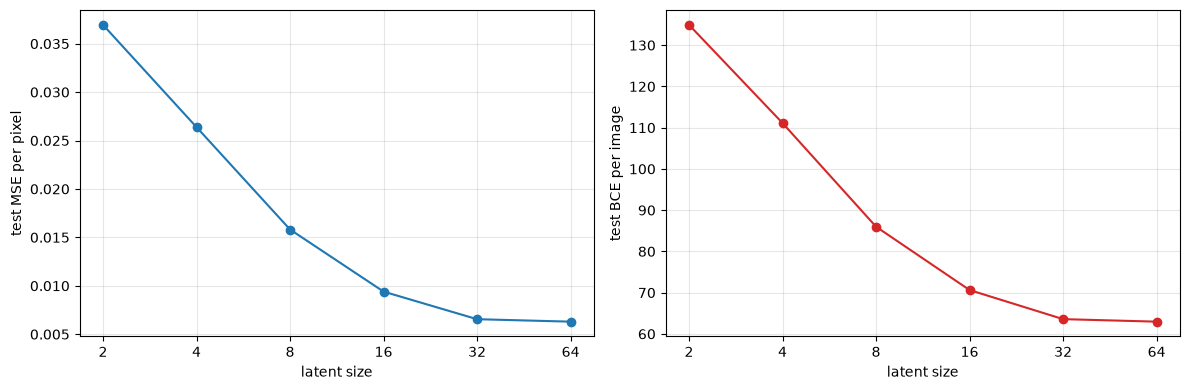

In [16]:
sizes = list(results.keys())
mse = [results[d]['mse'] for d in sizes]
bce = [results[d]['bce'] for d in sizes]
ticks = [f'{d}' for d in sizes]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(sizes, mse, 'o-')
plt.xscale('log', base=2)
plt.xticks(sizes, ticks)
plt.xlabel('latent size')
plt.ylabel('test MSE per pixel')
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
plt.plot(sizes, bce, 'o-', color='tab:red')
plt.xscale('log', base=2)
plt.xticks(sizes, ticks)
plt.xlabel('latent size')
plt.ylabel('test BCE per image')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

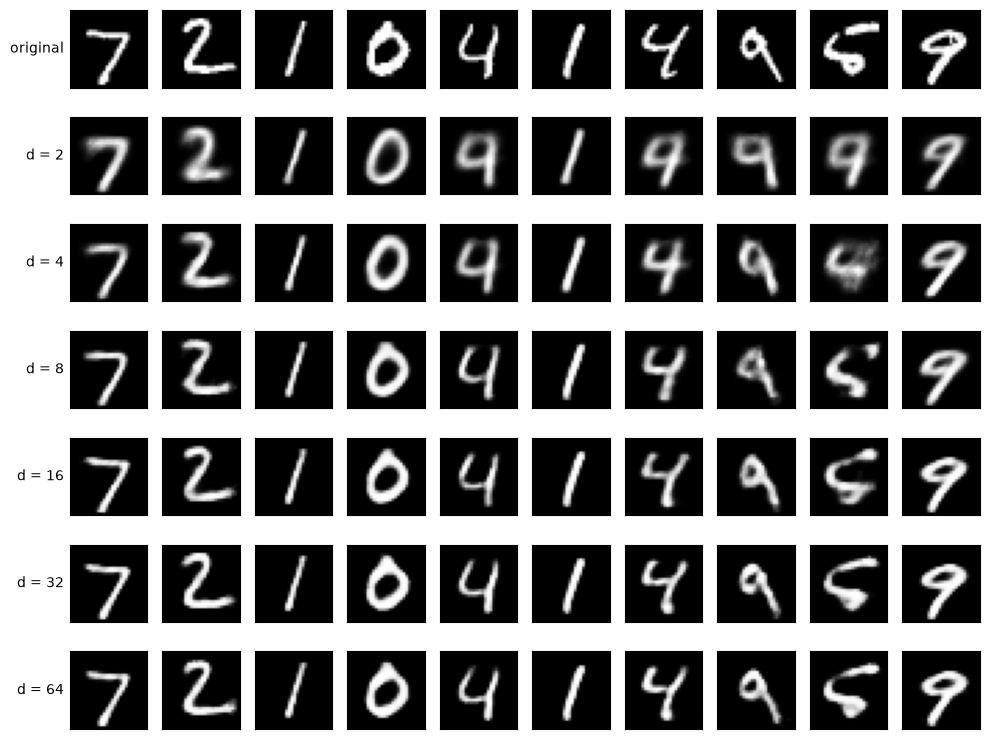

In [13]:
x, _ = next(iter(test_loader))
x = x[:10].to(device)
rows = [x.cpu()]
with torch.no_grad():
    for d in sizes:
        models[d].eval()
        rows.append(models[d](x).cpu())
labels = ['original'] + [f'd = {d}' for d in sizes]
fig, axes = plt.subplots(len(rows), 10, figsize=(10, len(rows) * 1.1))
for r, imgs in enumerate(rows):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c, 0], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(labels[r], rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()

As expected, smaller latent space compressed images more and the output of the decoder becomes blurry. The bigger the latent space is, the sharper the outputs are.

With d=2 the model keeps only rough shape of a number and as seen in reconstruction similar digits get mixed up - 4 and 5 are reconstructed as 9. d=4 is better yet still get some digits mixed up.

From d=16 reconstructions are quite close to the originals with MSE lower than 0.01

But it also seems that for this simple MNIST task the difference between d= 32 and d=64 is not that crussial. So for MNIST 16 or 32 dimensions is enough

# Variational Autoencoder (VAE)

In [17]:
LATENT_DIM = 16
BETA = 1.0

In [18]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid(),
        )
    def encode(self, x):
        h = self.encoder(x.view(x.size(0), -1))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar
    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, self.latent_dim, device=next(self.parameters()).device)
        return self.decode(z)


vae = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(device)
x, _ = next(iter(train_loader))
x = x.to(device)
x_hat, mu, logvar = vae(x)
print(x_hat.shape, mu.shape, logvar.shape)
print(vae.sample(8).shape)

torch.Size([256, 1, 28, 28]) torch.Size([256, 16]) torch.Size([256, 16])
torch.Size([8, 1, 28, 28])


In [20]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + beta * kl, recon, kl

def train_vae_epoch(model, optimizer, epoch, beta=BETA):
    model.train()
    totals = [0, 0, 0]
    for i, (x, _) in enumerate(train_loader):
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for j, v in enumerate([loss, recon, kl]):
            totals[j] += v.item() * x.size(0)
        if i % LOG_INTERVAL == 0:
            print(f'epoch {epoch} [{i}/{len(train_loader)}] loss {loss.item():.2f} recon {recon.item():.2f} kl {kl.item():.2f}')
    n = len(train_loader.dataset)
    return [t / n for t in totals]

@torch.no_grad()
def evaluate_vae(model, loader, beta=1.0):
    model.eval()
    totals = [0, 0, 0]
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
        for j, v in enumerate([loss, recon, kl]):
            totals[j] += v.item() * x.size(0)
    n = len(loader.dataset)
    return [t / n for t in totals]

In [23]:
vae = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(device)
optimizer = optim.Adam(vae.parameters(), lr=LR)
print(train_vae_epoch(vae, optimizer, 1))
print(evaluate_vae(vae, val_loader))

epoch 1 [0/215] loss 543.53 recon 543.51 kl 0.03
epoch 1 [50/215] loss 207.16 recon 205.70 kl 1.46
epoch 1 [100/215] loss 192.46 recon 189.37 kl 3.10
epoch 1 [150/215] loss 184.58 recon 179.28 kl 5.30
epoch 1 [200/215] loss 168.11 recon 159.36 kl 8.75
[201.82518072620738, 197.71858223322087, 4.106598689087955]
[164.63760378417967, 155.52829714355468, 9.10930619506836]


In [49]:
VAE_EPOCHS = 30
SAMPLE_INTERVAL = 5
DATASET = 'mnist'

In [25]:
def show_samples(model, title, n=64, path=None):
    model.eval()
    imgs = model.sample(n).cpu()
    grid = vutils.make_grid(imgs, nrow=8)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis('off')
    if path:
        plt.savefig(path)
    plt.show()

epoch 1 [0/215] loss 543.41 recon 543.37 kl 0.04
epoch 1 [50/215] loss 204.69 recon 203.40 kl 1.29
epoch 1 [100/215] loss 198.27 recon 195.65 kl 2.62
epoch 1 [150/215] loss 185.47 recon 180.40 kl 5.07
epoch 1 [200/215] loss 171.74 recon 162.79 kl 8.95
epoch 1 train 202.03 | val 164.07 (recon 154.94, kl 9.13)
epoch 2 [0/215] loss 164.93 recon 155.49 kl 9.44
epoch 2 [50/215] loss 151.51 recon 139.65 kl 11.86
epoch 2 [100/215] loss 143.69 recon 131.30 kl 12.39
epoch 2 [150/215] loss 141.54 recon 128.40 kl 13.14
epoch 2 [200/215] loss 133.70 recon 120.27 kl 13.43
epoch 2 train 143.83 | val 133.21 (recon 119.40, kl 13.81)
epoch 3 [0/215] loss 134.86 recon 121.27 kl 13.60
epoch 3 [50/215] loss 134.17 recon 119.96 kl 14.21
epoch 3 [100/215] loss 127.90 recon 113.29 kl 14.61
epoch 3 [150/215] loss 123.29 recon 108.63 kl 14.66
epoch 3 [200/215] loss 123.69 recon 108.59 kl 15.10
epoch 3 train 127.96 | val 124.26 (recon 108.96, kl 15.30)
epoch 4 [0/215] loss 124.27 recon 108.71 kl 15.56
epoch 4 [

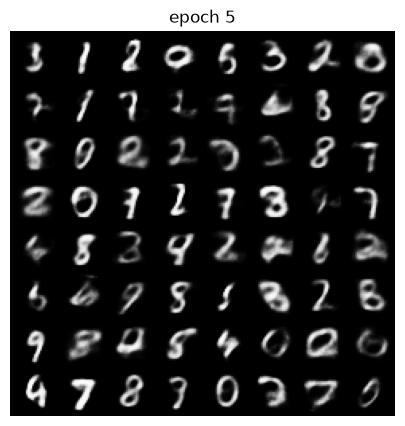

epoch 6 [0/215] loss 113.52 recon 96.21 kl 17.31
epoch 6 [50/215] loss 114.53 recon 97.06 kl 17.47
epoch 6 [100/215] loss 110.00 recon 93.24 kl 16.76
epoch 6 [150/215] loss 112.71 recon 95.01 kl 17.70
epoch 6 [200/215] loss 111.54 recon 93.99 kl 17.56
epoch 6 train 113.03 | val 112.25 (recon 94.99, kl 17.26)
epoch 7 [0/215] loss 112.69 recon 95.31 kl 17.38
epoch 7 [50/215] loss 111.74 recon 94.13 kl 17.61
epoch 7 [100/215] loss 108.57 recon 91.32 kl 17.25
epoch 7 [150/215] loss 110.58 recon 92.96 kl 17.62
epoch 7 [200/215] loss 110.64 recon 92.89 kl 17.75
epoch 7 train 110.89 | val 110.98 (recon 93.18, kl 17.79)
epoch 8 [0/215] loss 111.87 recon 93.94 kl 17.92
epoch 8 [50/215] loss 106.46 recon 88.34 kl 18.11
epoch 8 [100/215] loss 108.61 recon 90.70 kl 17.91
epoch 8 [150/215] loss 109.37 recon 91.29 kl 18.08
epoch 8 [200/215] loss 108.32 recon 90.27 kl 18.05
epoch 8 train 109.27 | val 109.29 (recon 90.75, kl 18.54)
epoch 9 [0/215] loss 106.93 recon 88.40 kl 18.52
epoch 9 [50/215] loss

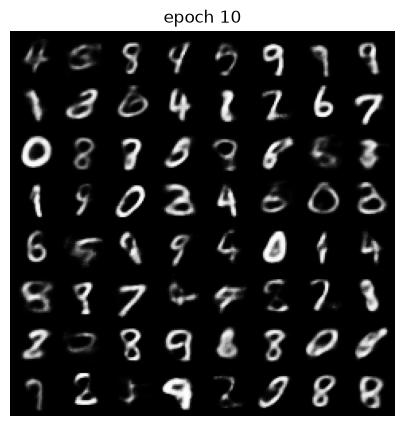

epoch 11 [0/215] loss 104.80 recon 86.30 kl 18.50
epoch 11 [50/215] loss 104.86 recon 86.28 kl 18.58
epoch 11 [100/215] loss 107.02 recon 87.94 kl 19.08
epoch 11 [150/215] loss 104.45 recon 85.60 kl 18.85
epoch 11 [200/215] loss 106.84 recon 88.19 kl 18.64
epoch 11 train 106.13 | val 106.77 (recon 87.98, kl 18.79)
epoch 12 [0/215] loss 104.70 recon 85.64 kl 19.06
epoch 12 [50/215] loss 106.17 recon 87.81 kl 18.36
epoch 12 [100/215] loss 103.64 recon 84.94 kl 18.71
epoch 12 [150/215] loss 104.28 recon 85.72 kl 18.55
epoch 12 [200/215] loss 107.14 recon 88.17 kl 18.97
epoch 12 train 105.48 | val 105.98 (recon 87.00, kl 18.98)
epoch 13 [0/215] loss 105.40 recon 86.07 kl 19.34
epoch 13 [50/215] loss 104.50 recon 85.40 kl 19.10
epoch 13 [100/215] loss 106.11 recon 86.93 kl 19.18
epoch 13 [150/215] loss 104.70 recon 85.89 kl 18.81
epoch 13 [200/215] loss 103.71 recon 84.81 kl 18.91
epoch 13 train 104.83 | val 105.80 (recon 86.69, kl 19.10)
epoch 14 [0/215] loss 103.88 recon 84.60 kl 19.28
ep

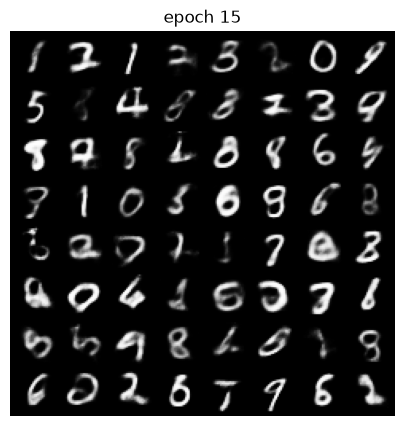

epoch 16 [0/215] loss 102.47 recon 83.05 kl 19.42
epoch 16 [50/215] loss 100.95 recon 81.60 kl 19.35
epoch 16 [100/215] loss 101.19 recon 82.02 kl 19.18
epoch 16 [150/215] loss 101.79 recon 82.73 kl 19.06
epoch 16 [200/215] loss 99.99 recon 80.69 kl 19.30
epoch 16 train 103.30 | val 104.23 (recon 84.98, kl 19.25)
epoch 17 [0/215] loss 104.21 recon 84.83 kl 19.38
epoch 17 [50/215] loss 100.75 recon 81.17 kl 19.58
epoch 17 [100/215] loss 100.64 recon 81.96 kl 18.68
epoch 17 [150/215] loss 99.76 recon 80.30 kl 19.46
epoch 17 [200/215] loss 102.88 recon 83.44 kl 19.44
epoch 17 train 102.88 | val 103.82 (recon 84.58, kl 19.24)
epoch 18 [0/215] loss 103.76 recon 84.38 kl 19.39
epoch 18 [50/215] loss 102.25 recon 82.87 kl 19.39
epoch 18 [100/215] loss 103.32 recon 83.78 kl 19.54
epoch 18 [150/215] loss 101.63 recon 82.36 kl 19.27
epoch 18 [200/215] loss 102.05 recon 82.35 kl 19.70
epoch 18 train 102.51 | val 103.75 (recon 84.34, kl 19.41)
epoch 19 [0/215] loss 101.07 recon 81.86 kl 19.21
epoc

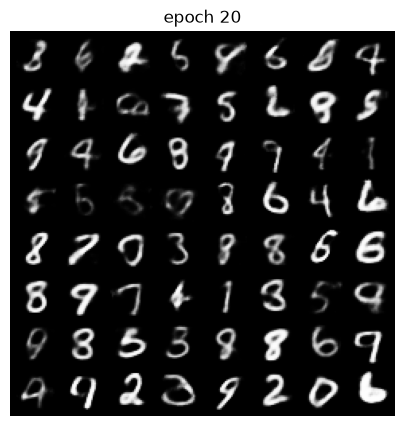

epoch 21 [0/215] loss 97.89 recon 78.51 kl 19.39
epoch 21 [50/215] loss 102.57 recon 83.08 kl 19.49
epoch 21 [100/215] loss 101.06 recon 80.83 kl 20.23
epoch 21 [150/215] loss 101.23 recon 81.34 kl 19.89
epoch 21 [200/215] loss 102.62 recon 82.69 kl 19.93
epoch 21 train 101.48 | val 102.94 (recon 83.00, kl 19.95)
epoch 22 [0/215] loss 100.44 recon 80.43 kl 20.00
epoch 22 [50/215] loss 102.77 recon 82.48 kl 20.29
epoch 22 [100/215] loss 105.48 recon 85.74 kl 19.74
epoch 22 [150/215] loss 101.18 recon 81.40 kl 19.78
epoch 22 [200/215] loss 100.72 recon 80.88 kl 19.83
epoch 22 train 101.14 | val 102.15 (recon 82.61, kl 19.54)
epoch 23 [0/215] loss 102.03 recon 82.03 kl 20.00
epoch 23 [50/215] loss 102.67 recon 82.59 kl 20.08
epoch 23 [100/215] loss 99.92 recon 79.90 kl 20.02
epoch 23 [150/215] loss 101.87 recon 81.45 kl 20.42
epoch 23 [200/215] loss 99.48 recon 79.80 kl 19.68
epoch 23 train 100.76 | val 102.15 (recon 82.71, kl 19.44)
epoch 24 [0/215] loss 97.98 recon 78.62 kl 19.35
epoch 

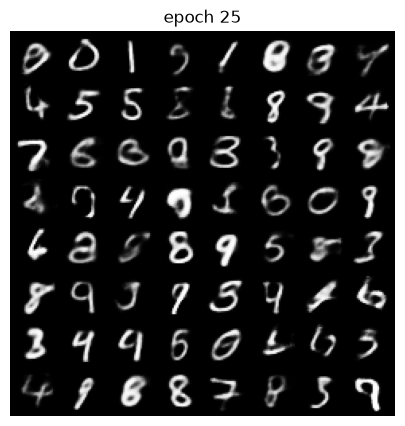

epoch 26 [0/215] loss 99.73 recon 79.65 kl 20.08
epoch 26 [50/215] loss 98.69 recon 78.73 kl 19.96
epoch 26 [100/215] loss 102.32 recon 82.03 kl 20.29
epoch 26 [150/215] loss 99.31 recon 79.42 kl 19.89
epoch 26 [200/215] loss 97.05 recon 77.32 kl 19.73
epoch 26 train 100.03 | val 101.56 (recon 81.30, kl 20.26)
epoch 27 [0/215] loss 99.82 recon 79.43 kl 20.39
epoch 27 [50/215] loss 99.47 recon 79.25 kl 20.22
epoch 27 [100/215] loss 97.97 recon 77.79 kl 20.18
epoch 27 [150/215] loss 100.09 recon 80.00 kl 20.09
epoch 27 [200/215] loss 98.59 recon 78.52 kl 20.06
epoch 27 train 99.85 | val 101.45 (recon 81.59, kl 19.86)
epoch 28 [0/215] loss 96.77 recon 77.03 kl 19.74
epoch 28 [50/215] loss 100.22 recon 79.98 kl 20.24
epoch 28 [100/215] loss 98.60 recon 78.40 kl 20.21
epoch 28 [150/215] loss 101.71 recon 81.13 kl 20.58
epoch 28 [200/215] loss 99.55 recon 79.30 kl 20.25
epoch 28 train 99.64 | val 101.10 (recon 80.64, kl 20.46)
epoch 29 [0/215] loss 100.85 recon 80.51 kl 20.34
epoch 29 [50/21

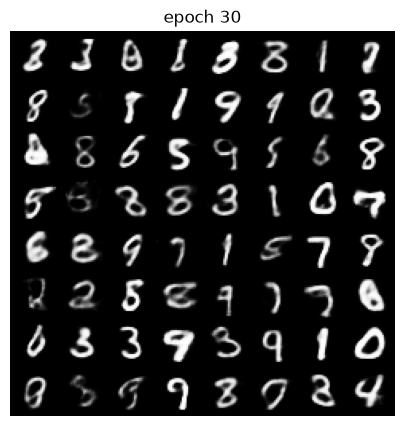

test: -ELBO 100.31, recon 79.83, kl 20.47


In [26]:
vae = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(device)
optimizer = optim.Adam(vae.parameters(), lr=LR)
results_dir = f'results_vae_{DATASET}'
os.makedirs(results_dir, exist_ok=True)
history = {'train': [], 'val': []}
best_val = float('inf')

for epoch in range(1, VAE_EPOCHS + 1):
    train_stats = train_vae_epoch(vae, optimizer, epoch)
    val_stats = evaluate_vae(vae, val_loader)
    history['train'].append(train_stats)
    history['val'].append(val_stats)
    print(f'epoch {epoch} train {train_stats[0]:.2f} | val {val_stats[0]:.2f} (recon {val_stats[1]:.2f}, kl {val_stats[2]:.2f})')
    if val_stats[0] < best_val:
        best_val = val_stats[0]
        torch.save(vae.state_dict(), f'best_vae_{DATASET}.pth')
    if epoch % SAMPLE_INTERVAL == 0:
        show_samples(vae, f'epoch {epoch}', path=f'{results_dir}/samples_{epoch}.png')
vae.load_state_dict(torch.load(f'best_vae_{DATASET}.pth'))
test_stats = evaluate_vae(vae, test_loader)
print(f'test: -ELBO {test_stats[0]:.2f}, recon {test_stats[1]:.2f}, kl {test_stats[2]:.2f}')

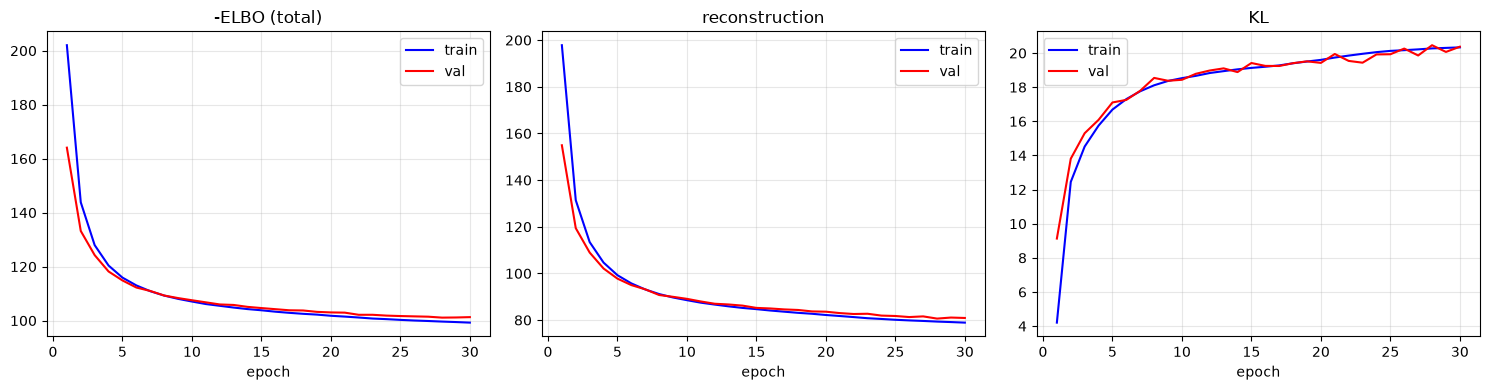

In [ ]:
epochs = range(1, VAE_EPOCHS + 1)
names = ['-ELBO (total)', 'reconstruction', 'KL']
plt.figure(figsize=(15, 4))
for j, name in enumerate(names):
    plt.subplot(1, 3, j + 1)
    plt.plot(epochs, [s[j] for s in history['train']], 'b-', label='train')
    plt.plot(epochs, [s[j] for s in history['val']], 'r-', label='val')
    plt.xlabel('epoch')
    plt.title(name)
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

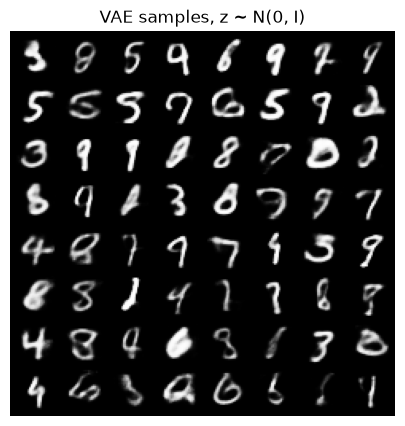

In [28]:
show_samples(vae, 'VAE samples, z ~ N(0, I)', n=64, path=f'{results_dir}/samples_best.png')

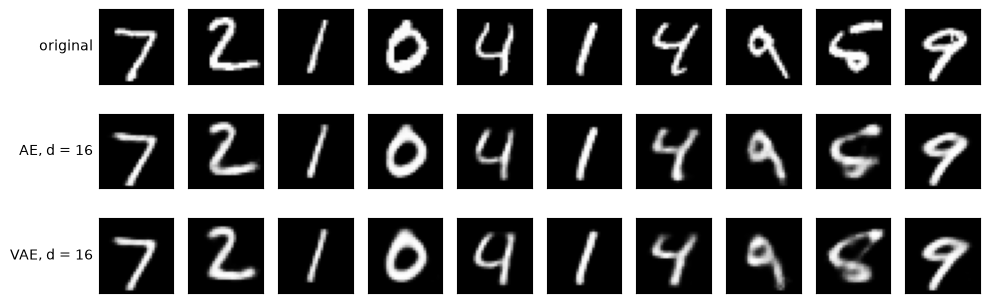

In [31]:
x, _ = next(iter(test_loader))
x = x[:10].to(device)
vae.eval()
with torch.no_grad():
    mu, _ = vae.encode(x)
    rows = [x.cpu(), models[16](x).cpu(), vae.decode(mu).cpu()]
labels = ['original', 'AE, d = 16', 'VAE, d = 16']
fig, axes = plt.subplots(3, 10, figsize=(10, 3.4))
for r, imgs in enumerate(rows):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c, 0], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(labels[r], rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()

In [32]:
vae2 = VAE(INPUT_DIM, HIDDEN_DIM, 2).to(device)
opt2 = optim.Adam(vae2.parameters(), lr=LR)
for epoch in range(1, VAE_EPOCHS + 1):
    train_vae_epoch(vae2, opt2, epoch)
print(evaluate_vae(vae2, test_loader))
torch.save(vae2.state_dict(), f'vae2d_{DATASET}.pth')

epoch 1 [0/215] loss 545.50 recon 545.49 kl 0.01
epoch 1 [50/215] loss 202.77 recon 200.17 kl 2.60
epoch 1 [100/215] loss 194.07 recon 191.42 kl 2.65
epoch 1 [150/215] loss 178.82 recon 174.77 kl 4.06
epoch 1 [200/215] loss 170.55 recon 165.96 kl 4.60
epoch 2 [0/215] loss 175.77 recon 171.15 kl 4.62
epoch 2 [50/215] loss 165.78 recon 160.88 kl 4.89
epoch 2 [100/215] loss 168.88 recon 163.82 kl 5.06
epoch 2 [150/215] loss 168.66 recon 164.05 kl 4.61
epoch 2 [200/215] loss 163.79 recon 158.62 kl 5.17
epoch 3 [0/215] loss 161.54 recon 156.31 kl 5.23
epoch 3 [50/215] loss 162.91 recon 157.78 kl 5.13
epoch 3 [100/215] loss 159.51 recon 154.23 kl 5.29
epoch 3 [150/215] loss 157.66 recon 152.35 kl 5.31
epoch 3 [200/215] loss 162.68 recon 157.08 kl 5.60
epoch 4 [0/215] loss 157.67 recon 152.14 kl 5.53
epoch 4 [50/215] loss 153.44 recon 147.83 kl 5.61
epoch 4 [100/215] loss 156.27 recon 150.58 kl 5.69
epoch 4 [150/215] loss 159.02 recon 153.42 kl 5.60
epoch 4 [200/215] loss 161.59 recon 155.95 

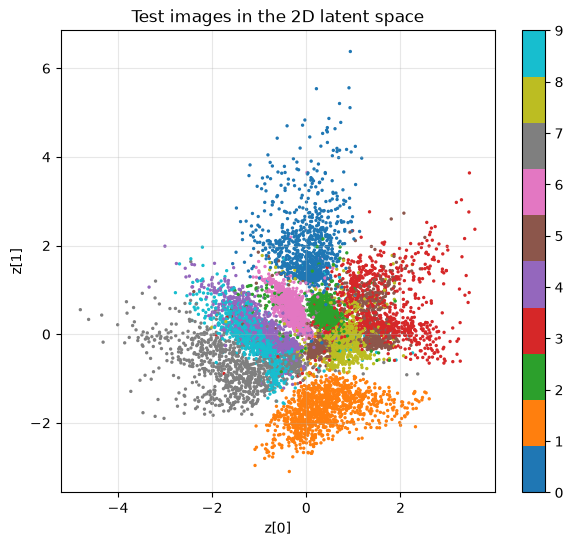

In [33]:
vae2.eval()
mus, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = vae2.encode(x.to(device))
        mus.append(mu.cpu())
        labels.append(y)
mus = torch.cat(mus)
labels = torch.cat(labels)
plt.figure(figsize=(7, 6))
plt.scatter(mus[:, 0], mus[:, 1], c=labels, cmap='tab10', s=2)
plt.colorbar(ticks=range(10))
plt.xlabel('z[0]')
plt.ylabel('z[1]')
plt.title('Test images in the 2D latent space')
plt.grid(True, alpha=0.3)
plt.show()

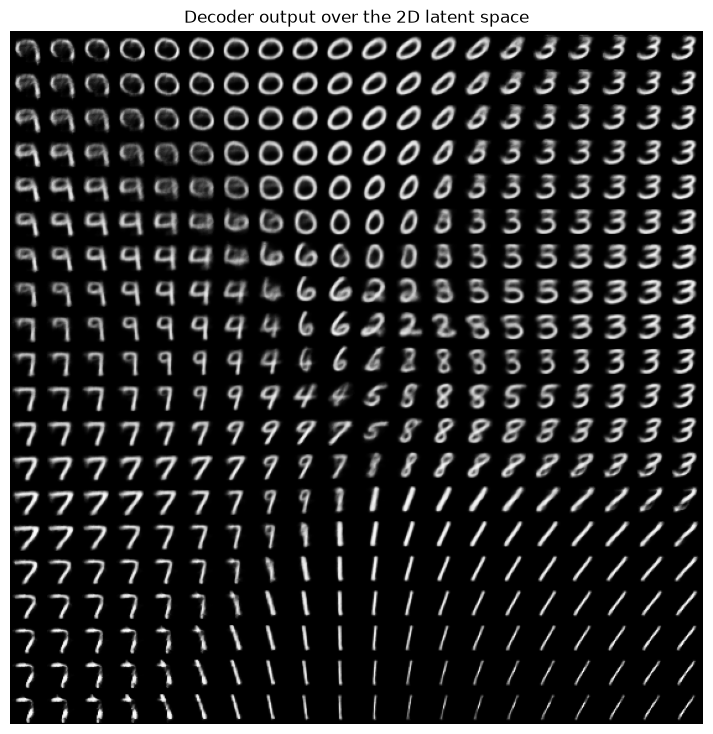

In [34]:
n = 20
vals = torch.linspace(-3, 3, n)
zs = torch.tensor([[a, b] for b in vals.flip(0) for a in vals], device=device)
with torch.no_grad():
    imgs = vae2.decode(zs).cpu()
plt.figure(figsize=(9, 9))
plt.imshow(vutils.make_grid(imgs, nrow=n, padding=0).permute(1, 2, 0))
plt.title('Decoder output over the 2D latent space')
plt.axis('off')
plt.show()

#### Fashion MNIST

In [35]:
import json
with open('vae_test_mnist.json', 'w') as f:
    json.dump(test_stats, f)

In [36]:
DATASET = 'fashion'
CLASSES = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']
train_full = datasets.FashionMNIST(root='./data_fashion', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='./data_fashion', train=False, download=True, transform=transform)
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)

100.0%
100.0%
100.0%
100.0%


epoch 1 [0/108] loss 544.15 recon 544.11 kl 0.04
epoch 1 [50/108] loss 318.03 recon 310.30 kl 7.73
epoch 1 [100/108] loss 289.39 recon 277.84 kl 11.56
epoch 1 train 338.37 | val 289.43 (recon 276.93, kl 12.50)
epoch 2 [0/108] loss 283.75 recon 271.59 kl 12.16
epoch 2 [50/108] loss 278.37 recon 266.92 kl 11.44
epoch 2 [100/108] loss 265.05 recon 254.02 kl 11.03
epoch 2 train 276.40 | val 266.86 (recon 255.29, kl 11.57)
epoch 3 [0/108] loss 270.37 recon 258.77 kl 11.60
epoch 3 [50/108] loss 267.14 recon 256.04 kl 11.10
epoch 3 [100/108] loss 257.10 recon 246.03 kl 11.06
epoch 3 train 260.98 | val 257.96 (recon 247.21, kl 10.76)
epoch 4 [0/108] loss 262.45 recon 251.39 kl 11.06
epoch 4 [50/108] loss 257.06 recon 246.25 kl 10.82
epoch 4 [100/108] loss 255.84 recon 245.34 kl 10.50
epoch 4 train 255.10 | val 254.35 (recon 243.44, kl 10.91)
epoch 5 [0/108] loss 253.43 recon 242.52 kl 10.91
epoch 5 [50/108] loss 251.75 recon 241.17 kl 10.59
epoch 5 [100/108] loss 254.94 recon 243.89 kl 11.05
e

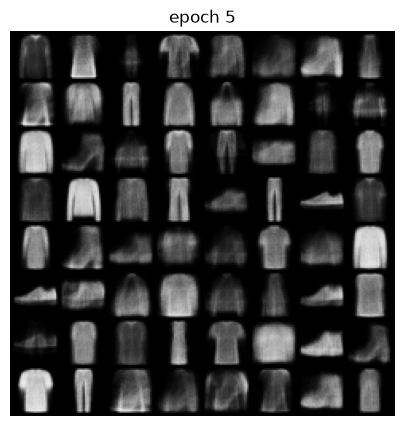

epoch 6 [0/108] loss 252.56 recon 241.57 kl 11.00
epoch 6 [50/108] loss 246.83 recon 235.91 kl 10.92
epoch 6 [100/108] loss 248.30 recon 236.84 kl 11.46
epoch 6 train 249.82 | val 249.69 (recon 238.46, kl 11.23)
epoch 7 [0/108] loss 249.53 recon 238.60 kl 10.92
epoch 7 [50/108] loss 244.16 recon 233.05 kl 11.11
epoch 7 [100/108] loss 249.33 recon 238.26 kl 11.08
epoch 7 train 248.10 | val 248.26 (recon 236.71, kl 11.55)
epoch 8 [0/108] loss 243.55 recon 232.20 kl 11.35
epoch 8 [50/108] loss 247.54 recon 236.34 kl 11.20
epoch 8 [100/108] loss 243.38 recon 231.95 kl 11.43
epoch 8 train 246.84 | val 247.50 (recon 236.44, kl 11.06)
epoch 9 [0/108] loss 243.98 recon 232.97 kl 11.01
epoch 9 [50/108] loss 242.28 recon 230.82 kl 11.46
epoch 9 [100/108] loss 244.32 recon 232.90 kl 11.42
epoch 9 train 245.89 | val 246.29 (recon 234.91, kl 11.38)
epoch 10 [0/108] loss 242.63 recon 231.42 kl 11.21
epoch 10 [50/108] loss 247.60 recon 236.37 kl 11.24
epoch 10 [100/108] loss 239.95 recon 228.09 kl 11

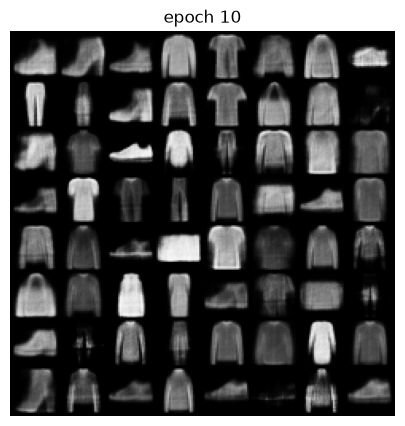

epoch 11 [0/108] loss 250.40 recon 238.67 kl 11.74
epoch 11 [50/108] loss 245.82 recon 234.93 kl 10.89
epoch 11 [100/108] loss 242.60 recon 231.12 kl 11.48
epoch 11 train 244.44 | val 244.98 (recon 233.37, kl 11.61)
epoch 12 [0/108] loss 237.78 recon 226.23 kl 11.56
epoch 12 [50/108] loss 246.88 recon 235.59 kl 11.29
epoch 12 [100/108] loss 237.42 recon 225.84 kl 11.58
epoch 12 train 243.91 | val 244.50 (recon 232.98, kl 11.52)
epoch 13 [0/108] loss 246.41 recon 235.04 kl 11.37
epoch 13 [50/108] loss 238.32 recon 226.47 kl 11.86
epoch 13 [100/108] loss 241.53 recon 230.04 kl 11.49
epoch 13 train 243.30 | val 243.97 (recon 232.35, kl 11.61)
epoch 14 [0/108] loss 246.35 recon 234.82 kl 11.54
epoch 14 [50/108] loss 246.01 recon 234.17 kl 11.84
epoch 14 [100/108] loss 239.54 recon 227.60 kl 11.94
epoch 14 train 242.96 | val 243.66 (recon 231.88, kl 11.78)
epoch 15 [0/108] loss 242.04 recon 230.39 kl 11.65
epoch 15 [50/108] loss 244.06 recon 232.65 kl 11.41
epoch 15 [100/108] loss 240.88 re

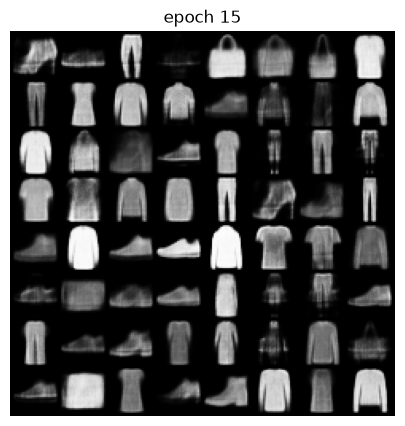

epoch 16 [0/108] loss 236.28 recon 224.75 kl 11.53
epoch 16 [50/108] loss 246.78 recon 235.20 kl 11.58
epoch 16 [100/108] loss 247.19 recon 234.71 kl 12.48
epoch 16 train 242.09 | val 243.04 (recon 231.21, kl 11.84)
epoch 17 [0/108] loss 242.22 recon 230.60 kl 11.63
epoch 17 [50/108] loss 241.03 recon 229.02 kl 12.02
epoch 17 [100/108] loss 244.18 recon 232.70 kl 11.48
epoch 17 train 241.76 | val 242.52 (recon 230.85, kl 11.67)
epoch 18 [0/108] loss 240.76 recon 229.06 kl 11.70
epoch 18 [50/108] loss 244.80 recon 232.94 kl 11.86
epoch 18 [100/108] loss 237.81 recon 225.43 kl 12.37
epoch 18 train 241.45 | val 242.38 (recon 230.58, kl 11.80)
epoch 19 [0/108] loss 240.12 recon 228.39 kl 11.72
epoch 19 [50/108] loss 245.83 recon 233.88 kl 11.95
epoch 19 [100/108] loss 237.88 recon 225.87 kl 12.00
epoch 19 train 241.25 | val 242.22 (recon 230.14, kl 12.09)
epoch 20 [0/108] loss 242.12 recon 230.13 kl 11.99
epoch 20 [50/108] loss 237.80 recon 225.47 kl 12.32
epoch 20 [100/108] loss 241.48 re

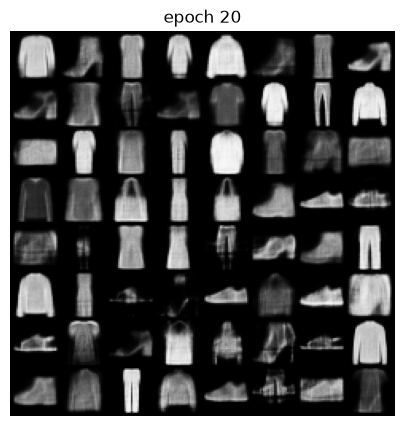

epoch 21 [0/108] loss 240.20 recon 227.93 kl 12.28
epoch 21 [50/108] loss 243.70 recon 231.83 kl 11.87
epoch 21 [100/108] loss 242.46 recon 230.56 kl 11.90
epoch 21 train 240.63 | val 241.46 (recon 229.67, kl 11.79)
epoch 22 [0/108] loss 233.37 recon 221.55 kl 11.82
epoch 22 [50/108] loss 244.07 recon 232.27 kl 11.80
epoch 22 [100/108] loss 242.71 recon 230.68 kl 12.03
epoch 22 train 240.49 | val 241.46 (recon 229.70, kl 11.76)
epoch 23 [0/108] loss 240.65 recon 228.86 kl 11.79
epoch 23 [50/108] loss 241.87 recon 229.41 kl 12.46
epoch 23 [100/108] loss 238.65 recon 226.67 kl 11.98
epoch 23 train 240.22 | val 241.13 (recon 229.08, kl 12.06)
epoch 24 [0/108] loss 241.87 recon 229.83 kl 12.04
epoch 24 [50/108] loss 241.70 recon 229.23 kl 12.48
epoch 24 [100/108] loss 245.28 recon 233.00 kl 12.29
epoch 24 train 239.97 | val 240.89 (recon 228.36, kl 12.53)
epoch 25 [0/108] loss 239.22 recon 226.81 kl 12.42
epoch 25 [50/108] loss 239.88 recon 227.49 kl 12.39
epoch 25 [100/108] loss 239.96 re

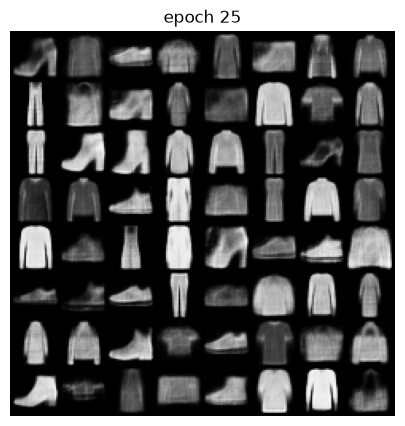

epoch 26 [0/108] loss 243.54 recon 231.24 kl 12.30
epoch 26 [50/108] loss 241.21 recon 228.70 kl 12.50
epoch 26 [100/108] loss 235.02 recon 222.40 kl 12.63
epoch 26 train 239.54 | val 240.51 (recon 227.41, kl 13.10)
epoch 27 [0/108] loss 240.71 recon 227.60 kl 13.10
epoch 27 [50/108] loss 239.46 recon 226.91 kl 12.56
epoch 27 [100/108] loss 235.40 recon 222.93 kl 12.46
epoch 27 train 239.39 | val 240.29 (recon 228.06, kl 12.23)
epoch 28 [0/108] loss 239.92 recon 227.78 kl 12.13
epoch 28 [50/108] loss 238.54 recon 225.83 kl 12.72
epoch 28 [100/108] loss 238.29 recon 226.21 kl 12.08
epoch 28 train 239.18 | val 240.36 (recon 227.38, kl 12.98)
epoch 29 [0/108] loss 239.69 recon 226.68 kl 13.01
epoch 29 [50/108] loss 238.02 recon 225.47 kl 12.56
epoch 29 [100/108] loss 238.44 recon 225.90 kl 12.54
epoch 29 train 239.08 | val 240.11 (recon 227.70, kl 12.41)
epoch 30 [0/108] loss 237.44 recon 225.09 kl 12.36
epoch 30 [50/108] loss 238.36 recon 225.48 kl 12.88
epoch 30 [100/108] loss 242.99 re

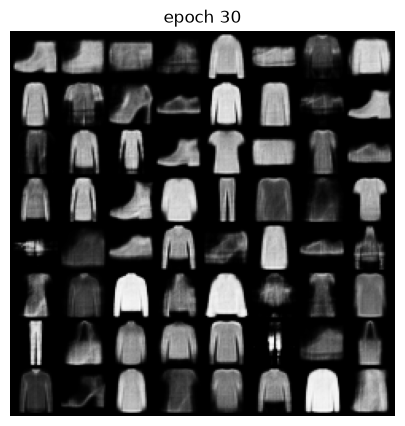

test: -ELBO 241.11, recon 228.44, kl 12.67


In [37]:
vae_f = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(device)
opt_f = optim.Adam(vae_f.parameters(), lr=LR)
results_dir = f'results_vae_{DATASET}'
os.makedirs(results_dir, exist_ok=True)
history_f = {'train': [], 'val': []}
best_val = float('inf')
for epoch in range(1, VAE_EPOCHS + 1):
    train_stats = train_vae_epoch(vae_f, opt_f, epoch)
    val_stats = evaluate_vae(vae_f, val_loader)
    history_f['train'].append(train_stats)
    history_f['val'].append(val_stats)
    print(f'epoch {epoch} train {train_stats[0]:.2f} | val {val_stats[0]:.2f} (recon {val_stats[1]:.2f}, kl {val_stats[2]:.2f})')
    if val_stats[0] < best_val:
        best_val = val_stats[0]
        torch.save(vae_f.state_dict(), f'best_vae_{DATASET}.pth')
    if epoch % SAMPLE_INTERVAL == 0:
        show_samples(vae_f, f'epoch {epoch}', path=f'{results_dir}/samples_{epoch}.png')
vae_f.load_state_dict(torch.load(f'best_vae_{DATASET}.pth'))
test_stats_f = evaluate_vae(vae_f, test_loader)
with open('vae_test_fashion.json', 'w') as f:
    json.dump(test_stats_f, f)
print(f'test: -ELBO {test_stats_f[0]:.2f}, recon {test_stats_f[1]:.2f}, kl {test_stats_f[2]:.2f}')

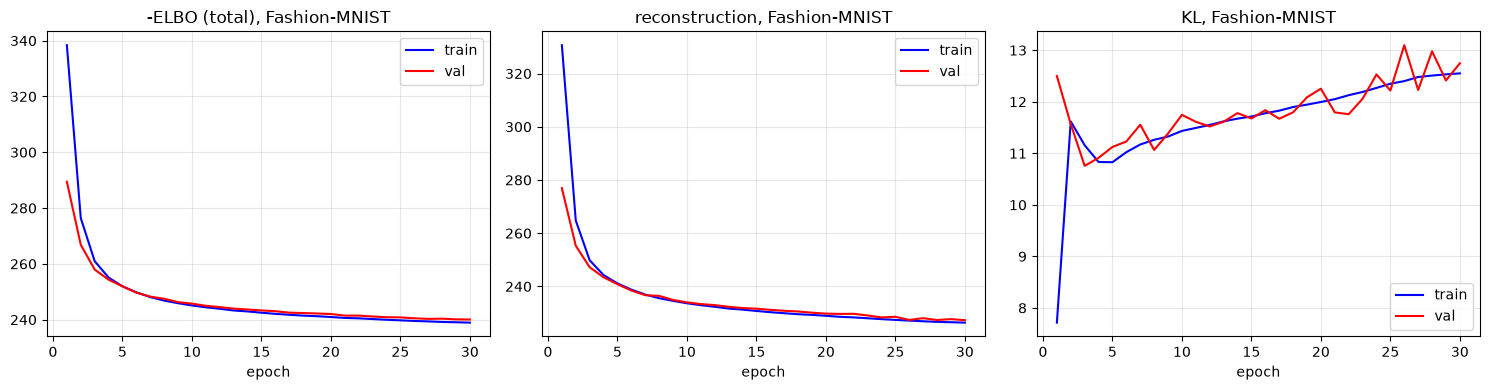

In [38]:
epochs = range(1, VAE_EPOCHS + 1)
names = ['-ELBO (total)', 'reconstruction', 'KL']
plt.figure(figsize=(15, 4))
for j, name in enumerate(names):
    plt.subplot(1, 3, j + 1)
    plt.plot(epochs, [s[j] for s in history_f['train']], 'b-', label='train')
    plt.plot(epochs, [s[j] for s in history_f['val']], 'r-', label='val')
    plt.xlabel('epoch')
    plt.title(f'{name}, Fashion-MNIST')
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

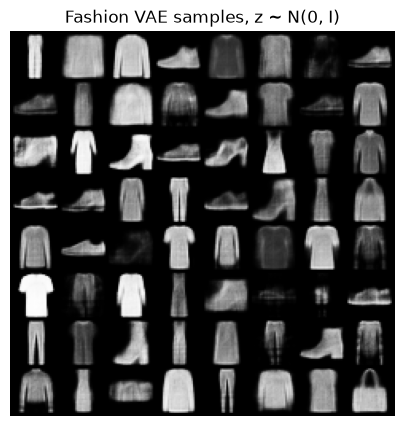

In [39]:
show_samples(vae_f, 'Fashion VAE samples, z ~ N(0, I)', n=64, path=f'{results_dir}/samples_best.png')

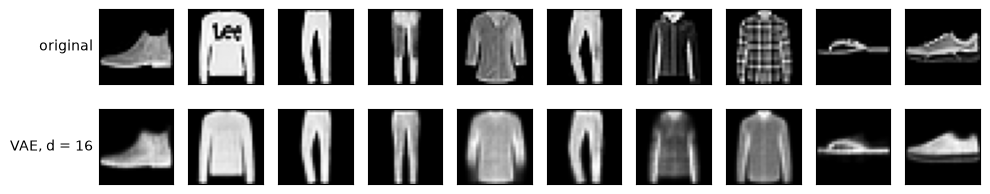

In [40]:
x, _ = next(iter(test_loader))
x = x[:10].to(device)
vae_f.eval()
with torch.no_grad():
    mu, _ = vae_f.encode(x)
    rows = [x.cpu(), vae_f.decode(mu).cpu()]
labels = ['original', 'VAE, d = 16']
fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
for r, imgs in enumerate(rows):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c, 0], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(labels[r], rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()

               -ELBO     recon        KL
mnist         100.31     79.83     20.47
fashion       241.11    228.44     12.67


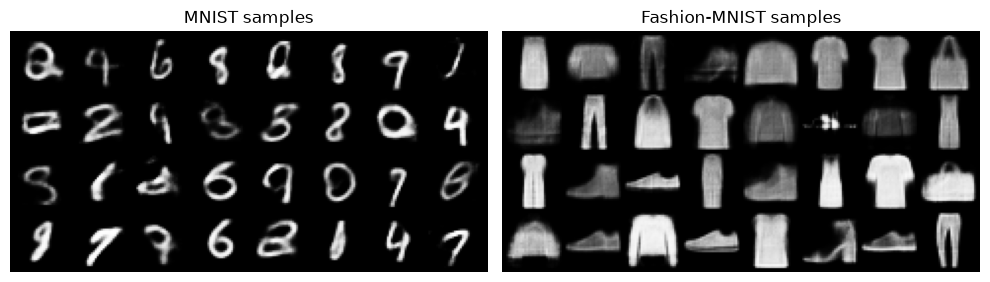

In [41]:
res = {}
for name in ['mnist', 'fashion']:
    with open(f'vae_test_{name}.json') as f:
        res[name] = json.load(f)
print(f'{"":10}{"-ELBO":>10}{"recon":>10}{"KL":>10}')
for name, (total, recon, kl) in res.items():
    print(f'{name:10}{total:10.2f}{recon:10.2f}{kl:10.2f}')
plt.figure(figsize=(10, 5))
for i, (model, title) in enumerate([(vae, 'MNIST'), (vae_f, 'Fashion-MNIST')]):
    model.eval()
    imgs = model.sample(32).cpu()
    plt.subplot(1, 2, i + 1)
    plt.imshow(vutils.make_grid(imgs, nrow=8).permute(1, 2, 0))
    plt.title(f'{title} samples')
    plt.axis('off')
plt.tight_layout()
plt.show()

## f-VAE:

In [50]:
FLOW_HIDDEN = 128
FLOW_LAYERS = 6

In [43]:
class VecCoupling(nn.Module):
    def __init__(self, dim, hidden, mask):
        super().__init__()
        self.register_buffer('mask', mask)
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2 * dim),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)
        self.scale = nn.Parameter(torch.ones(dim))
    def st(self, z_masked):
        s, t = self.net(z_masked).chunk(2, dim=1)
        return self.scale * torch.tanh(s) * (1 - self.mask), t * (1 - self.mask)
    def forward(self, z):
        s, t = self.st(z * self.mask)
        return z * torch.exp(s) + t, s.sum(dim=1)
    def inverse(self, u):
        s, t = self.st(u * self.mask)
        return (u - t) * torch.exp(-s)

class LatentFlow(nn.Module):
    def __init__(self, dim, hidden, n_layers):
        super().__init__()
        base = (torch.arange(dim) % 2).float()
        self.layers = nn.ModuleList([VecCoupling(dim, hidden, base if i % 2 == 0 else 1 - base) for i in range(n_layers)])
    def forward(self, z):
        ldj = 0
        for layer in self.layers:
            z, d = layer(z)
            ldj = ldj + d
        return z, ldj
    def inverse(self, u):
        for layer in reversed(self.layers):
            u = layer.inverse(u)
        return u

In [44]:
flow = LatentFlow(LATENT_DIM, FLOW_HIDDEN, FLOW_LAYERS).to(device)
for p in flow.parameters():
    p.data.normal_(0, 0.1)
z = torch.randn(8, LATENT_DIM, device=device)
u, ldj = flow(z)
print(u.shape, ldj.shape, torch.allclose(flow.inverse(u), z, atol=1e-5))

torch.Size([8, 16]) torch.Size([8]) True


In [45]:
class FVAE(VAE):
    def __init__(self, input_dim, hidden_dim, latent_dim, flow_hidden, flow_layers):
        super().__init__(input_dim, hidden_dim, latent_dim)
        self.flow = LatentFlow(latent_dim, flow_hidden, flow_layers)
    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps
        return self.decode(z), mu, logvar, z, eps
    def log_prior(self, z):
        u, ldj = self.flow(z)
        return (-0.5 * (u ** 2 + math.log(2 * math.pi))).sum(dim=1) + ldj
    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        u = temperature * torch.randn(n, self.latent_dim, device=next(self.parameters()).device)
        return self.decode(self.flow.inverse(u))

In [46]:
def fvae_loss(model, x, beta=1.0):
    x_hat, mu, logvar, z, eps = model(x)
    recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / x.size(0)
    log_q = (-0.5 * (math.log(2 * math.pi) + logvar + eps ** 2)).sum(dim=1)
    kl = (log_q - model.log_prior(z)).mean()
    return recon + beta * kl, recon, kl

In [48]:
def train_fvae_epoch(model, optimizer, epoch, beta=BETA):
    model.train()
    totals = [0, 0, 0]
    for i, (x, _) in enumerate(train_loader):
        x = x.to(device)
        loss, recon, kl = fvae_loss(model, x, beta)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 100.0)
        optimizer.step()
        for j, v in enumerate([loss, recon, kl]):
            totals[j] += v.item() * x.size(0)
        if i % LOG_INTERVAL == 0:
            print(f'epoch {epoch} [{i}/{len(train_loader)}] loss {loss.item():.2f} recon {recon.item():.2f} kl {kl.item():.2f}')
    n = len(train_loader.dataset)
    return [t / n for t in totals]

@torch.no_grad()
def evaluate_fvae(model, loader, beta=1.0):
    model.eval()
    totals = [0, 0, 0]
    for x, _ in loader:
        x = x.to(device)
        loss, recon, kl = fvae_loss(model, x, beta)
        for j, v in enumerate([loss, recon, kl]):
            totals[j] += v.item() * x.size(0)
    n = len(loader.dataset)
    return [t / n for t in totals]

### Fashion mnist

In [68]:
DATASET = 'fashion'
train_full = datasets.FashionMNIST(root='./data_fashion', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='./data_fashion', train=False, download=True, transform=transform)
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
print(DATASET, type(train_full).__name__)

fashion FashionMNIST


epoch 1 [0/108] loss 544.27 recon 544.26 kl 0.01
epoch 1 [50/108] loss 323.78 recon 316.81 kl 6.97
epoch 1 [100/108] loss 283.43 recon 277.02 kl 6.40
epoch 1 train 336.43 | val 284.73 (recon 277.95, kl 6.78)
epoch 2 [0/108] loss 279.65 recon 272.84 kl 6.81
epoch 2 [50/108] loss 266.43 recon 259.32 kl 7.10
epoch 2 [100/108] loss 260.00 recon 252.35 kl 7.65
epoch 2 train 270.05 | val 261.47 (recon 253.47, kl 8.00)
epoch 3 [0/108] loss 261.30 recon 253.08 kl 8.22
epoch 3 [50/108] loss 254.71 recon 246.40 kl 8.31
epoch 3 [100/108] loss 245.05 recon 236.60 kl 8.45
epoch 3 train 256.57 | val 255.20 (recon 246.86, kl 8.35)
epoch 4 [0/108] loss 257.21 recon 248.80 kl 8.41
epoch 4 [50/108] loss 252.73 recon 244.34 kl 8.39
epoch 4 [100/108] loss 259.60 recon 250.84 kl 8.77
epoch 4 train 252.54 | val 251.86 (recon 243.17, kl 8.68)
epoch 5 [0/108] loss 250.77 recon 242.08 kl 8.70
epoch 5 [50/108] loss 247.71 recon 238.70 kl 9.02
epoch 5 [100/108] loss 246.72 recon 237.69 kl 9.03
epoch 5 train 249.

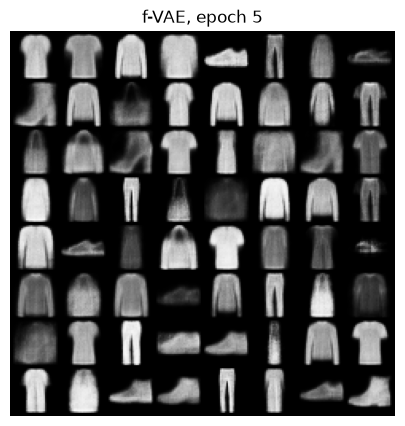

epoch 6 [0/108] loss 252.30 recon 243.29 kl 9.01
epoch 6 [50/108] loss 251.62 recon 242.34 kl 9.27
epoch 6 [100/108] loss 251.37 recon 242.23 kl 9.14
epoch 6 train 248.11 | val 248.68 (recon 239.28, kl 9.39)
epoch 7 [0/108] loss 247.49 recon 238.17 kl 9.32
epoch 7 [50/108] loss 241.39 recon 232.10 kl 9.29
epoch 7 [100/108] loss 246.91 recon 237.42 kl 9.49
epoch 7 train 246.79 | val 247.11 (recon 237.48, kl 9.63)
epoch 8 [0/108] loss 244.36 recon 234.82 kl 9.54
epoch 8 [50/108] loss 241.29 recon 231.80 kl 9.49
epoch 8 [100/108] loss 241.96 recon 232.40 kl 9.56
epoch 8 train 245.76 | val 246.13 (recon 236.38, kl 9.75)
epoch 9 [0/108] loss 243.10 recon 233.49 kl 9.62
epoch 9 [50/108] loss 248.94 recon 239.39 kl 9.55
epoch 9 [100/108] loss 242.53 recon 232.74 kl 9.79
epoch 9 train 244.94 | val 245.53 (recon 235.52, kl 10.01)
epoch 10 [0/108] loss 242.99 recon 232.72 kl 10.28
epoch 10 [50/108] loss 249.04 recon 239.00 kl 10.04
epoch 10 [100/108] loss 252.23 recon 241.40 kl 10.83
epoch 10 tr

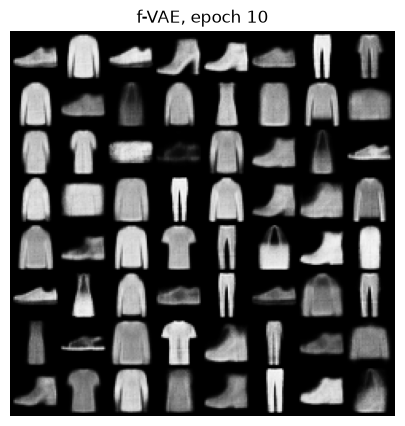

epoch 11 [0/108] loss 237.87 recon 227.74 kl 10.13
epoch 11 [50/108] loss 239.37 recon 229.26 kl 10.11
epoch 11 [100/108] loss 236.23 recon 226.32 kl 9.91
epoch 11 train 243.25 | val 244.46 (recon 234.07, kl 10.38)
epoch 12 [0/108] loss 248.96 recon 238.76 kl 10.20
epoch 12 [50/108] loss 242.91 recon 232.54 kl 10.37
epoch 12 [100/108] loss 242.76 recon 232.24 kl 10.52
epoch 12 train 242.50 | val 243.52 (recon 232.79, kl 10.73)
epoch 13 [0/108] loss 243.36 recon 232.59 kl 10.76
epoch 13 [50/108] loss 241.38 recon 230.60 kl 10.79
epoch 13 [100/108] loss 235.38 recon 224.63 kl 10.75
epoch 13 train 241.90 | val 242.74 (recon 232.11, kl 10.63)
epoch 14 [0/108] loss 245.69 recon 235.07 kl 10.62
epoch 14 [50/108] loss 237.68 recon 227.09 kl 10.59
epoch 14 [100/108] loss 239.17 recon 228.12 kl 11.05
epoch 14 train 241.44 | val 242.14 (recon 231.32, kl 10.82)
epoch 15 [0/108] loss 241.63 recon 230.89 kl 10.74
epoch 15 [50/108] loss 243.19 recon 232.15 kl 11.05
epoch 15 [100/108] loss 237.76 rec

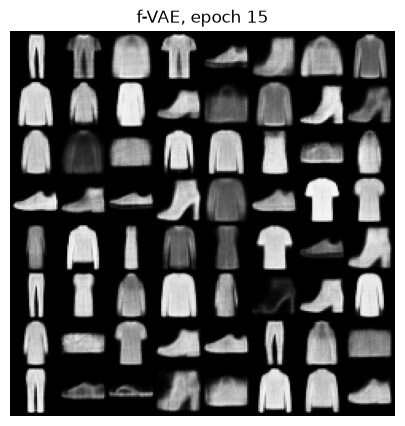

epoch 16 [0/108] loss 240.39 recon 229.65 kl 10.74
epoch 16 [50/108] loss 239.10 recon 228.02 kl 11.08
epoch 16 [100/108] loss 237.53 recon 226.53 kl 11.00
epoch 16 train 240.48 | val 241.12 (recon 230.02, kl 11.10)
epoch 17 [0/108] loss 238.56 recon 227.59 kl 10.97
epoch 17 [50/108] loss 241.59 recon 230.59 kl 10.99
epoch 17 [100/108] loss 239.34 recon 228.13 kl 11.22
epoch 17 train 240.01 | val 240.75 (recon 229.71, kl 11.03)
epoch 18 [0/108] loss 233.95 recon 223.06 kl 10.89
epoch 18 [50/108] loss 239.85 recon 228.57 kl 11.28
epoch 18 [100/108] loss 236.17 recon 224.84 kl 11.33
epoch 18 train 239.72 | val 240.65 (recon 229.32, kl 11.33)
epoch 19 [0/108] loss 241.48 recon 230.11 kl 11.37
epoch 19 [50/108] loss 233.16 recon 221.51 kl 11.64
epoch 19 [100/108] loss 240.96 recon 229.74 kl 11.22
epoch 19 train 239.38 | val 240.74 (recon 229.31, kl 11.43)
epoch 20 [0/108] loss 238.73 recon 227.19 kl 11.54
epoch 20 [50/108] loss 240.94 recon 229.57 kl 11.38
epoch 20 [100/108] loss 244.06 re

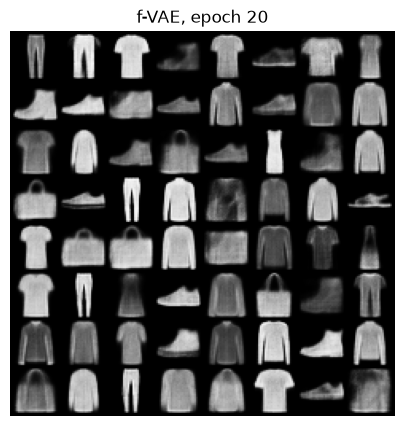

epoch 21 [0/108] loss 242.81 recon 231.36 kl 11.45
epoch 21 [50/108] loss 233.99 recon 222.71 kl 11.29
epoch 21 [100/108] loss 232.24 recon 220.82 kl 11.41
epoch 21 train 238.85 | val 239.64 (recon 228.07, kl 11.57)
epoch 22 [0/108] loss 241.70 recon 230.18 kl 11.53
epoch 22 [50/108] loss 235.24 recon 223.77 kl 11.47
epoch 22 [100/108] loss 244.24 recon 232.72 kl 11.52
epoch 22 train 238.62 | val 239.40 (recon 227.63, kl 11.76)
epoch 23 [0/108] loss 239.54 recon 228.07 kl 11.48
epoch 23 [50/108] loss 242.66 recon 230.71 kl 11.95
epoch 23 [100/108] loss 242.30 recon 230.65 kl 11.65
epoch 23 train 238.27 | val 239.48 (recon 227.72, kl 11.75)
epoch 24 [0/108] loss 247.08 recon 235.18 kl 11.90
epoch 24 [50/108] loss 234.94 recon 223.18 kl 11.75
epoch 24 [100/108] loss 235.76 recon 224.03 kl 11.73
epoch 24 train 238.04 | val 238.98 (recon 227.48, kl 11.51)
epoch 25 [0/108] loss 235.94 recon 224.53 kl 11.41
epoch 25 [50/108] loss 228.68 recon 217.02 kl 11.66
epoch 25 [100/108] loss 239.48 re

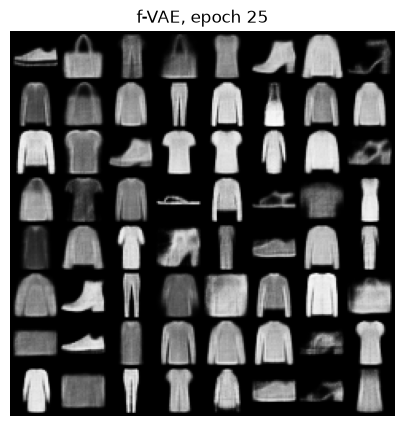

epoch 26 [0/108] loss 235.29 recon 223.46 kl 11.83
epoch 26 [50/108] loss 239.39 recon 227.42 kl 11.97
epoch 26 [100/108] loss 235.57 recon 223.68 kl 11.89
epoch 26 train 237.65 | val 238.60 (recon 226.71, kl 11.90)
epoch 27 [0/108] loss 238.52 recon 226.27 kl 12.25
epoch 27 [50/108] loss 239.65 recon 227.89 kl 11.76
epoch 27 [100/108] loss 238.28 recon 226.45 kl 11.83
epoch 27 train 237.49 | val 238.31 (recon 226.40, kl 11.91)
epoch 28 [0/108] loss 240.12 recon 228.07 kl 12.05
epoch 28 [50/108] loss 238.60 recon 226.81 kl 11.79
epoch 28 [100/108] loss 230.81 recon 218.90 kl 11.91
epoch 28 train 237.23 | val 238.14 (recon 226.36, kl 11.79)
epoch 29 [0/108] loss 237.29 recon 225.49 kl 11.80
epoch 29 [50/108] loss 238.49 recon 226.48 kl 12.01
epoch 29 [100/108] loss 235.45 recon 223.41 kl 12.04
epoch 29 train 237.12 | val 238.07 (recon 225.98, kl 12.09)
epoch 30 [0/108] loss 239.91 recon 227.98 kl 11.93
epoch 30 [50/108] loss 237.34 recon 225.01 kl 12.32
epoch 30 [100/108] loss 240.98 re

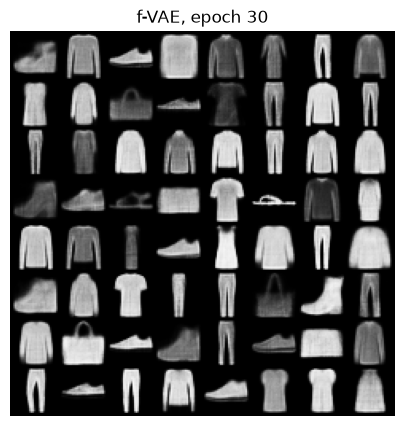

test: -ELBO 239.01, recon 227.25, kl 11.76


In [69]:
fvae_f = FVAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM, FLOW_HIDDEN, FLOW_LAYERS).to(device)
opt_fv = optim.Adam(fvae_f.parameters(), lr=LR)
results_dir = f'results_fvae_{DATASET}'
os.makedirs(results_dir, exist_ok=True)
history_fv = {'train': [], 'val': []}
best_val = float('inf')

for epoch in range(1, VAE_EPOCHS + 1):
    train_stats = train_fvae_epoch(fvae_f, opt_fv, epoch)
    val_stats = evaluate_fvae(fvae_f, val_loader)
    history_fv['train'].append(train_stats)
    history_fv['val'].append(val_stats)
    print(f'epoch {epoch} train {train_stats[0]:.2f} | val {val_stats[0]:.2f} (recon {val_stats[1]:.2f}, kl {val_stats[2]:.2f})')
    if val_stats[0] < best_val:
        best_val = val_stats[0]
        torch.save(fvae_f.state_dict(), f'best_fvae_{DATASET}.pth')
    if epoch % SAMPLE_INTERVAL == 0:
        show_samples(fvae_f, f'f-VAE, epoch {epoch}', path=f'{results_dir}/samples_{epoch}.png')
fvae_f.load_state_dict(torch.load(f'best_fvae_{DATASET}.pth'))
test_stats_fv = evaluate_fvae(fvae_f, test_loader)

with open(f'fvae_test_{DATASET}.json', 'w') as f:
    json.dump(test_stats_fv, f)
print(f'test: -ELBO {test_stats_fv[0]:.2f}, recon {test_stats_fv[1]:.2f}, kl {test_stats_fv[2]:.2f}')

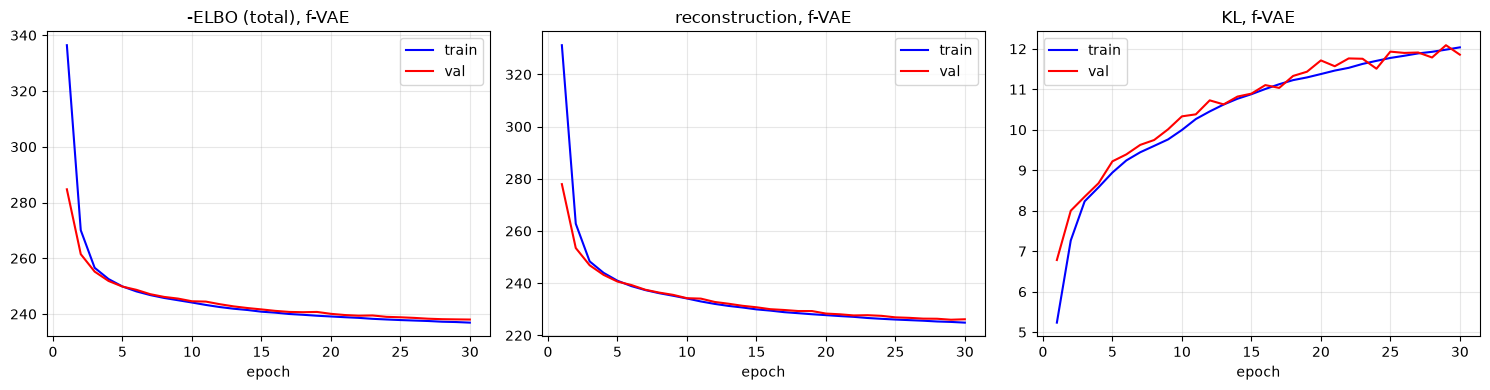

In [70]:
epochs = range(1, VAE_EPOCHS + 1)
names = ['-ELBO (total)', 'reconstruction', 'KL']
plt.figure(figsize=(15, 4))
for j, name in enumerate(names):
    plt.subplot(1, 3, j + 1)
    plt.plot(epochs, [s[j] for s in history_fv['train']], 'b-', label='train')
    plt.plot(epochs, [s[j] for s in history_fv['val']], 'r-', label='val')
    plt.xlabel('epoch')
    plt.title(f'{name}, f-VAE')
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

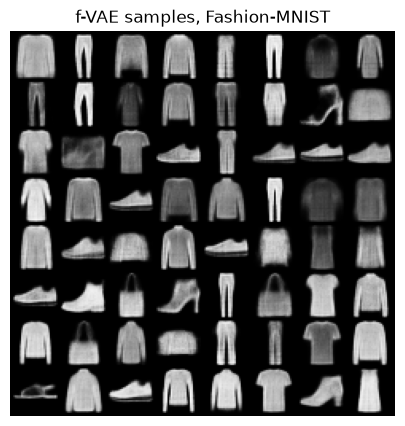

In [71]:
show_samples(fvae_f, 'f-VAE samples, Fashion-MNIST', n=64, path='results_fvae_fashion/samples_best.png')

fashion
             -ELBO     recon        KL
vae         241.11    228.44     12.67
fvae        239.01    227.25     11.76


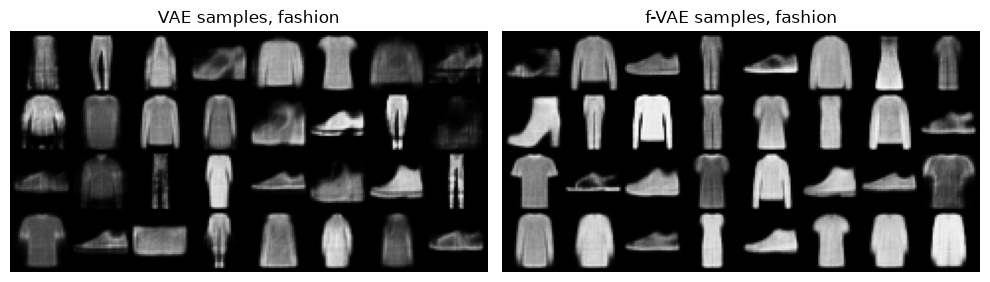

In [72]:
def compare_vae_fvae(vae_model, fvae_model, name):
    res = {}
    for kind in ['vae', 'fvae']:
        with open(f'{kind}_test_{name}.json') as f:
            res[kind] = json.load(f)
    print(f'{name}')
    print(f'{"":8}{"-ELBO":>10}{"recon":>10}{"KL":>10}')
    for kind, (total, recon, kl) in res.items():
        print(f'{kind:8}{total:10.2f}{recon:10.2f}{kl:10.2f}')
    plt.figure(figsize=(10, 5))
    for i, (model, title) in enumerate([(vae_model, 'VAE'), (fvae_model, 'f-VAE')]):
        model.eval()
        imgs = model.sample(32).cpu()
        plt.subplot(1, 2, i + 1)
        plt.imshow(vutils.make_grid(imgs, nrow=8).permute(1, 2, 0))
        plt.title(f'{title} samples, {name}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

compare_vae_fvae(vae_f, fvae_f, 'fashion')

### mnist

In [73]:
DATASET = 'mnist'
train_full = datasets.MNIST(root='./data_mnist', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data_mnist', train=False, download=True, transform=transform)
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
print(DATASET, type(train_full).__name__)

mnist MNIST


epoch 1 [0/108] loss 544.40 recon 544.38 kl 0.02
epoch 1 [50/108] loss 202.43 recon 200.92 kl 1.51
epoch 1 [100/108] loss 192.20 recon 189.27 kl 2.94
epoch 1 train 221.62 | val 188.30 (recon 184.77, kl 3.53)
epoch 2 [0/108] loss 188.40 recon 184.67 kl 3.74
epoch 2 [50/108] loss 165.41 recon 158.18 kl 7.22
epoch 2 [100/108] loss 151.79 recon 142.19 kl 9.60
epoch 2 train 165.37 | val 146.19 (recon 136.41, kl 9.78)
epoch 3 [0/108] loss 145.63 recon 135.70 kl 9.94
epoch 3 [50/108] loss 138.89 recon 128.49 kl 10.40
epoch 3 [100/108] loss 130.75 recon 119.39 kl 11.36
epoch 3 train 136.83 | val 131.48 (recon 120.11, kl 11.37)
epoch 4 [0/108] loss 133.75 recon 122.16 kl 11.60
epoch 4 [50/108] loss 126.89 recon 114.70 kl 12.19
epoch 4 [100/108] loss 121.15 recon 108.45 kl 12.69
epoch 4 train 126.57 | val 123.54 (recon 110.60, kl 12.94)
epoch 5 [0/108] loss 120.44 recon 107.59 kl 12.85
epoch 5 [50/108] loss 118.85 recon 104.87 kl 13.98
epoch 5 [100/108] loss 118.21 recon 104.04 kl 14.17
epoch 5 

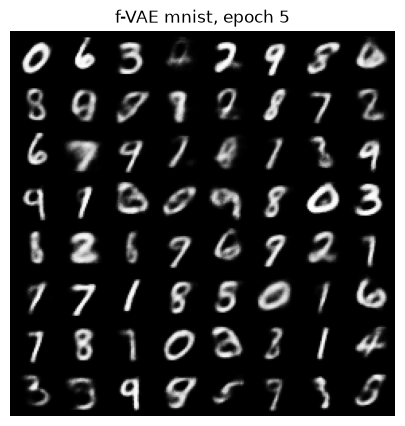

epoch 6 [0/108] loss 115.22 recon 101.03 kl 14.20
epoch 6 [50/108] loss 115.44 recon 100.86 kl 14.57
epoch 6 [100/108] loss 114.30 recon 99.39 kl 14.91
epoch 6 train 115.79 | val 114.89 (recon 99.76, kl 15.12)
epoch 7 [0/108] loss 115.55 recon 100.55 kl 15.01
epoch 7 [50/108] loss 115.50 recon 100.52 kl 14.99
epoch 7 [100/108] loss 109.74 recon 94.40 kl 15.34
epoch 7 train 112.79 | val 112.41 (recon 97.08, kl 15.33)
epoch 8 [0/108] loss 110.38 recon 94.93 kl 15.44
epoch 8 [50/108] loss 107.07 recon 91.81 kl 15.25
epoch 8 [100/108] loss 110.60 recon 94.35 kl 16.25
epoch 8 train 110.58 | val 110.63 (recon 94.97, kl 15.66)
epoch 9 [0/108] loss 109.76 recon 93.96 kl 15.80
epoch 9 [50/108] loss 108.80 recon 92.70 kl 16.10
epoch 9 [100/108] loss 107.72 recon 91.69 kl 16.03
epoch 9 train 108.83 | val 109.14 (recon 92.99, kl 16.15)
epoch 10 [0/108] loss 106.35 recon 90.18 kl 16.17
epoch 10 [50/108] loss 109.09 recon 92.75 kl 16.34
epoch 10 [100/108] loss 108.97 recon 92.60 kl 16.38
epoch 10 tr

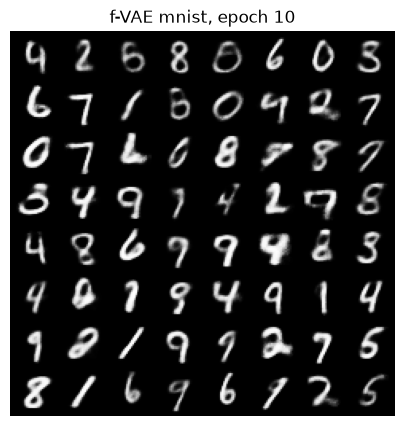

epoch 11 [0/108] loss 106.77 recon 90.47 kl 16.30
epoch 11 [50/108] loss 108.43 recon 91.83 kl 16.61
epoch 11 [100/108] loss 105.01 recon 88.21 kl 16.80
epoch 11 train 106.19 | val 106.63 (recon 89.77, kl 16.86)
epoch 12 [0/108] loss 104.86 recon 88.26 kl 16.60
epoch 12 [50/108] loss 103.57 recon 86.34 kl 17.23
epoch 12 [100/108] loss 107.21 recon 90.14 kl 17.07
epoch 12 train 105.16 | val 105.75 (recon 88.60, kl 17.15)
epoch 13 [0/108] loss 101.54 recon 84.67 kl 16.86
epoch 13 [50/108] loss 103.41 recon 86.53 kl 16.88
epoch 13 [100/108] loss 102.85 recon 85.48 kl 17.37
epoch 13 train 104.30 | val 104.84 (recon 87.45, kl 17.39)
epoch 14 [0/108] loss 102.10 recon 85.00 kl 17.10
epoch 14 [50/108] loss 102.89 recon 85.58 kl 17.31
epoch 14 [100/108] loss 102.99 recon 85.74 kl 17.25
epoch 14 train 103.53 | val 104.19 (recon 86.75, kl 17.45)
epoch 15 [0/108] loss 102.82 recon 85.15 kl 17.67
epoch 15 [50/108] loss 102.82 recon 85.07 kl 17.75
epoch 15 [100/108] loss 101.27 recon 83.83 kl 17.44

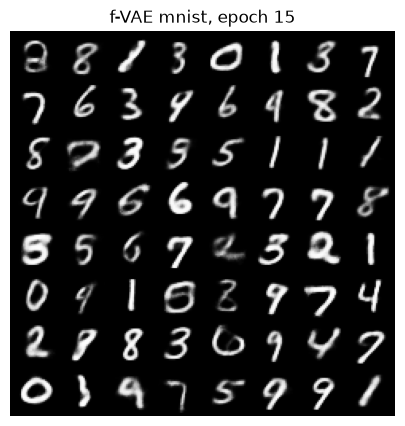

epoch 16 [0/108] loss 103.03 recon 85.01 kl 18.02
epoch 16 [50/108] loss 103.51 recon 85.81 kl 17.70
epoch 16 [100/108] loss 102.29 recon 84.77 kl 17.52
epoch 16 train 102.21 | val 103.15 (recon 85.67, kl 17.48)
epoch 17 [0/108] loss 101.14 recon 83.89 kl 17.24
epoch 17 [50/108] loss 101.96 recon 84.03 kl 17.93
epoch 17 [100/108] loss 99.18 recon 81.77 kl 17.40
epoch 17 train 101.69 | val 102.57 (recon 84.77, kl 17.80)
epoch 18 [0/108] loss 101.93 recon 83.85 kl 18.08
epoch 18 [50/108] loss 102.72 recon 85.04 kl 17.68
epoch 18 [100/108] loss 98.99 recon 81.54 kl 17.45
epoch 18 train 101.21 | val 102.00 (recon 84.05, kl 17.95)
epoch 19 [0/108] loss 101.19 recon 82.97 kl 18.22
epoch 19 [50/108] loss 101.97 recon 83.81 kl 18.16
epoch 19 [100/108] loss 102.41 recon 84.10 kl 18.30
epoch 19 train 100.66 | val 101.77 (recon 83.89, kl 17.88)
epoch 20 [0/108] loss 101.24 recon 83.17 kl 18.07
epoch 20 [50/108] loss 101.65 recon 83.63 kl 18.03
epoch 20 [100/108] loss 102.85 recon 84.44 kl 18.41
e

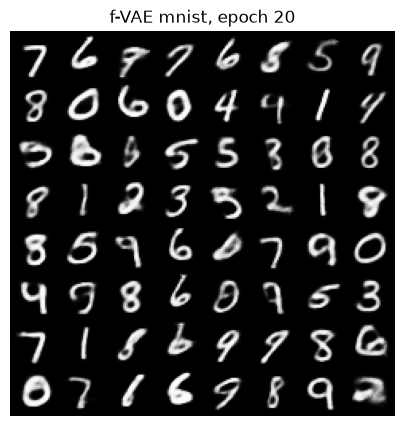

epoch 21 [0/108] loss 99.75 recon 81.57 kl 18.18
epoch 21 [50/108] loss 97.95 recon 80.25 kl 17.70
epoch 21 [100/108] loss 99.91 recon 81.45 kl 18.46
epoch 21 train 99.94 | val 100.91 (recon 82.67, kl 18.24)
epoch 22 [0/108] loss 100.93 recon 82.43 kl 18.49
epoch 22 [50/108] loss 102.29 recon 83.74 kl 18.55
epoch 22 [100/108] loss 99.96 recon 81.47 kl 18.49
epoch 22 train 99.50 | val 100.83 (recon 82.26, kl 18.57)
epoch 23 [0/108] loss 100.39 recon 81.72 kl 18.67
epoch 23 [50/108] loss 99.49 recon 81.31 kl 18.18
epoch 23 [100/108] loss 100.78 recon 82.25 kl 18.53
epoch 23 train 99.22 | val 100.54 (recon 81.90, kl 18.64)
epoch 24 [0/108] loss 99.52 recon 80.99 kl 18.54
epoch 24 [50/108] loss 99.81 recon 81.30 kl 18.51
epoch 24 [100/108] loss 98.12 recon 79.68 kl 18.44
epoch 24 train 98.84 | val 100.12 (recon 81.70, kl 18.42)
epoch 25 [0/108] loss 98.11 recon 79.84 kl 18.27
epoch 25 [50/108] loss 98.05 recon 79.37 kl 18.69
epoch 25 [100/108] loss 98.34 recon 80.12 kl 18.22
epoch 25 train

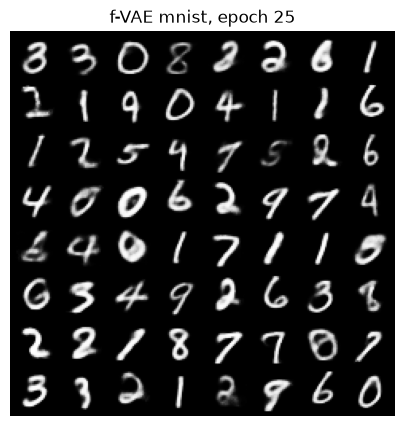

epoch 26 [0/108] loss 99.97 recon 81.13 kl 18.84
epoch 26 [50/108] loss 98.29 recon 79.71 kl 18.58
epoch 26 [100/108] loss 96.48 recon 77.68 kl 18.80
epoch 26 train 98.27 | val 99.75 (recon 81.11, kl 18.64)
epoch 27 [0/108] loss 98.79 recon 80.14 kl 18.65
epoch 27 [50/108] loss 97.48 recon 78.85 kl 18.63
epoch 27 [100/108] loss 96.83 recon 77.94 kl 18.89
epoch 27 train 98.00 | val 99.28 (recon 80.48, kl 18.80)
epoch 28 [0/108] loss 98.85 recon 80.10 kl 18.75
epoch 28 [50/108] loss 96.27 recon 77.56 kl 18.71
epoch 28 [100/108] loss 97.66 recon 79.03 kl 18.63
epoch 28 train 97.72 | val 99.20 (recon 80.09, kl 19.10)
epoch 29 [0/108] loss 96.82 recon 77.80 kl 19.02
epoch 29 [50/108] loss 96.17 recon 77.48 kl 18.69
epoch 29 [100/108] loss 96.29 recon 77.40 kl 18.89
epoch 29 train 97.52 | val 98.81 (recon 80.07, kl 18.75)
epoch 30 [0/108] loss 96.31 recon 78.11 kl 18.20
epoch 30 [50/108] loss 98.98 recon 80.02 kl 18.96
epoch 30 [100/108] loss 97.63 recon 78.65 kl 18.99
epoch 30 train 97.24 |

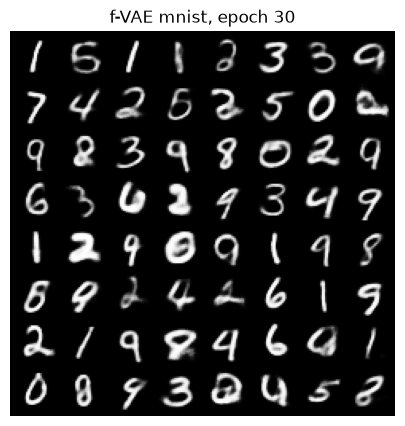

test: -ELBO 98.06, recon 79.25, kl 18.81


In [74]:
fvae = FVAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM, FLOW_HIDDEN, FLOW_LAYERS).to(device)
opt_fv = optim.Adam(fvae.parameters(), lr=LR)
results_dir = f'results_fvae_{DATASET}'
os.makedirs(results_dir, exist_ok=True)
history_fv = {'train': [], 'val': []}
best_val = float('inf')

for epoch in range(1, VAE_EPOCHS + 1):
    train_stats = train_fvae_epoch(fvae, opt_fv, epoch)
    val_stats = evaluate_fvae(fvae, val_loader)
    history_fv['train'].append(train_stats)
    history_fv['val'].append(val_stats)
    print(f'epoch {epoch} train {train_stats[0]:.2f} | val {val_stats[0]:.2f} (recon {val_stats[1]:.2f}, kl {val_stats[2]:.2f})')
    if val_stats[0] < best_val:
        best_val = val_stats[0]
        torch.save(fvae.state_dict(), f'best_fvae_{DATASET}.pth')
    if epoch % SAMPLE_INTERVAL == 0:
        show_samples(fvae, f'f-VAE {DATASET}, epoch {epoch}', path=f'{results_dir}/samples_{epoch}.png')
fvae.load_state_dict(torch.load(f'best_fvae_{DATASET}.pth'))
test_stats_fv = evaluate_fvae(fvae, test_loader)

with open(f'fvae_test_{DATASET}.json', 'w') as f:
    json.dump(test_stats_fv, f)
print(f'test: -ELBO {test_stats_fv[0]:.2f}, recon {test_stats_fv[1]:.2f}, kl {test_stats_fv[2]:.2f}')

mnist
             -ELBO     recon        KL
vae         100.31     79.83     20.47
fvae         98.06     79.25     18.81


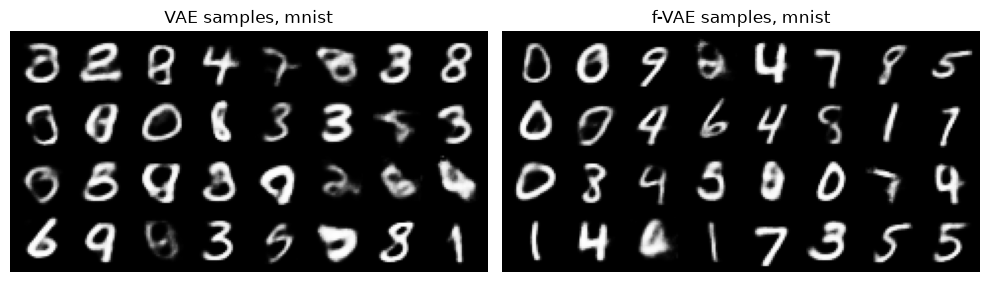

In [75]:
compare_vae_fvae(vae, fvae, 'mnist')

## β-VAE:

In [62]:
BETAS = [0.5, 1.0, 4.0, 8.0]
BETA_EPOCHS = 20
beta_models = {}
beta_results = {}
for b in BETAS:
    print(f'\nbeta = {b}')
    print('-' * 30)
    m = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(device)
    opt = optim.Adam(m.parameters(), lr=LR)
    for epoch in range(1, BETA_EPOCHS + 1):
        train_stats = train_vae_epoch(m, opt, epoch, beta=b)
        val_stats = evaluate_vae(m, val_loader, beta=b)
        print(f'epoch {epoch} train {train_stats[0]:.2f} | val {val_stats[0]:.2f} (recon {val_stats[1]:.2f}, kl {val_stats[2]:.2f})')
    beta_results[b] = evaluate_vae(m, test_loader, beta=1.0)
    beta_models[b] = m
    torch.save(m.state_dict(), f'beta_vae_{b}_mnist.pth')
    print(f'test: -ELBO {beta_results[b][0]:.2f}, recon {beta_results[b][1]:.2f}, kl {beta_results[b][2]:.2f}')


beta = 0.5
------------------------------
epoch 1 [0/108] loss 543.48 recon 543.47 kl 0.03
epoch 1 [50/108] loss 207.81 recon 206.48 kl 2.65
epoch 1 [100/108] loss 190.11 recon 187.11 kl 5.99
epoch 1 train 220.98 | val 187.54 (recon 184.26, kl 6.55)
epoch 2 [0/108] loss 190.62 recon 187.57 kl 6.11
epoch 2 [50/108] loss 170.74 recon 165.18 kl 11.13
epoch 2 [100/108] loss 145.71 recon 137.18 kl 17.07
epoch 2 train 168.18 | val 146.42 (recon 137.75, kl 17.34)
epoch 3 [0/108] loss 143.65 recon 134.65 kl 18.00
epoch 3 [50/108] loss 135.20 recon 126.04 kl 18.32
epoch 3 [100/108] loss 132.10 recon 122.17 kl 19.86
epoch 3 train 136.99 | val 129.18 (recon 119.21, kl 19.93)
epoch 4 [0/108] loss 128.59 recon 118.50 kl 20.17
epoch 4 [50/108] loss 123.60 recon 113.05 kl 21.10
epoch 4 [100/108] loss 117.69 recon 107.09 kl 21.20
epoch 4 train 123.91 | val 120.15 (recon 109.79, kl 20.73)
epoch 5 [0/108] loss 118.69 recon 108.38 kl 20.61
epoch 5 [50/108] loss 115.08 recon 104.20 kl 21.77
epoch 5 [100/

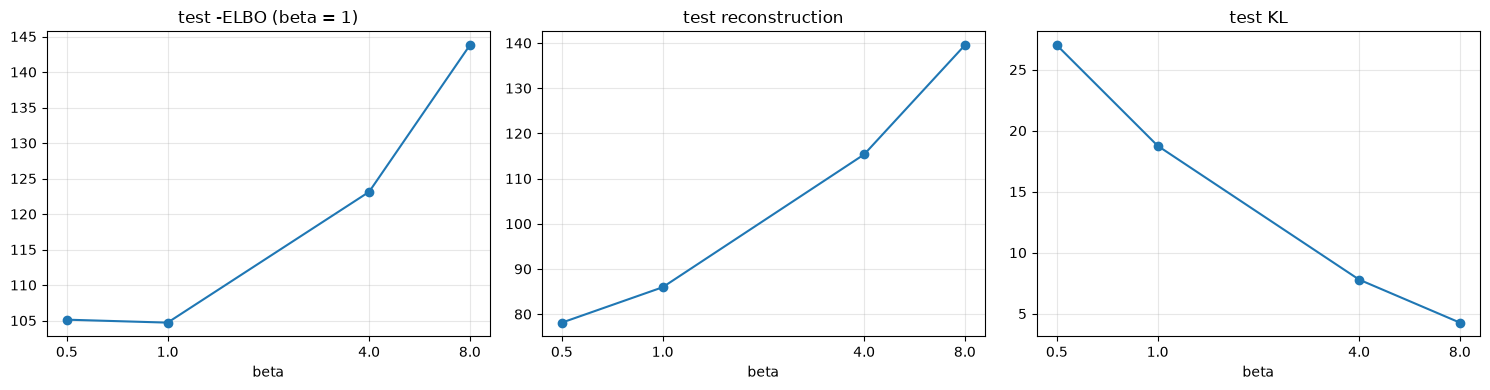

In [76]:
bs = list(beta_results.keys())
names = ['-ELBO (beta = 1)', 'reconstruction', 'KL']
plt.figure(figsize=(15, 4))
for j, name in enumerate(names):
    plt.subplot(1, 3, j + 1)
    plt.plot(bs, [beta_results[b][j] for b in bs], 'o-')
    plt.xscale('log', base=2)
    plt.xticks(bs, [str(b) for b in bs])
    plt.xlabel('beta')
    plt.title(f'test {name}')
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

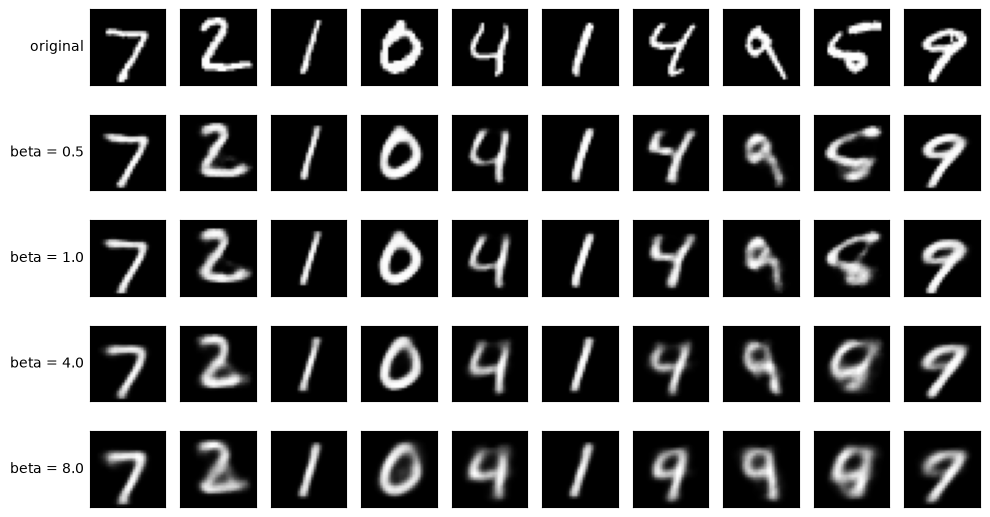

In [77]:
x, _ = next(iter(test_loader))
x = x[:10].to(device)
rows = [x.cpu()]
with torch.no_grad():
    for b in bs:
        beta_models[b].eval()
        mu, _ = beta_models[b].encode(x)
        rows.append(beta_models[b].decode(mu).cpu())
labels = ['original'] + [f'beta = {b}' for b in bs]
fig, axes = plt.subplots(len(rows), 10, figsize=(10, len(rows) * 1.1))
for r, imgs in enumerate(rows):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c, 0], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(labels[r], rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()

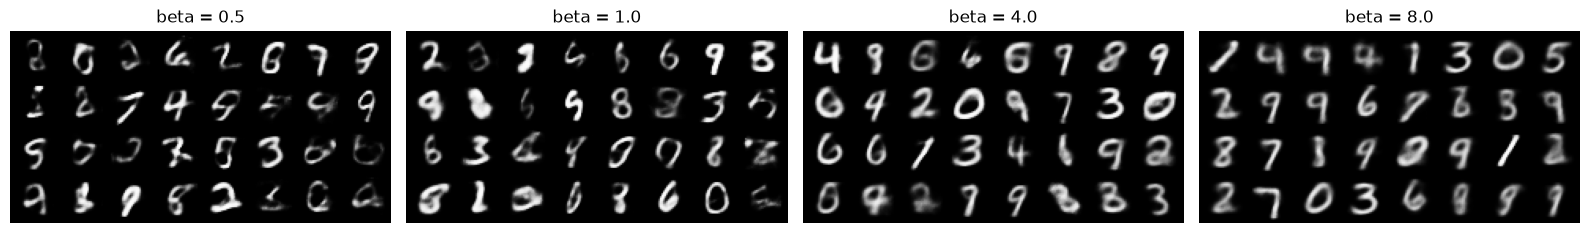

In [78]:
plt.figure(figsize=(16, 4))
for i, b in enumerate(bs):
    beta_models[b].eval()
    imgs = beta_models[b].sample(32).cpu()
    plt.subplot(1, len(bs), i + 1)
    plt.imshow(vutils.make_grid(imgs, nrow=8).permute(1, 2, 0))
    plt.title(f'beta = {b}')
    plt.axis('off')
plt.tight_layout()
plt.show()

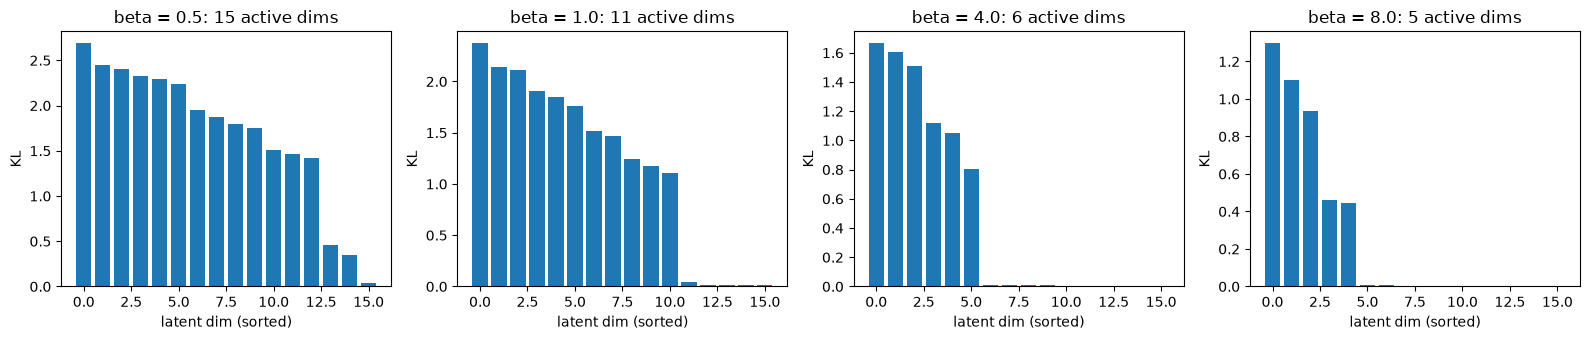

In [79]:
@torch.no_grad()
def kl_per_dim(model, loader):
    model.eval()
    total = torch.zeros(model.latent_dim)
    n = 0
    for x, _ in loader:
        mu, logvar = model.encode(x.to(device))
        total += (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).sum(dim=0).cpu()
        n += x.size(0)
    return total / n

kl_dims = {b: kl_per_dim(beta_models[b], test_loader) for b in bs}
plt.figure(figsize=(16, 3.5))
for i, b in enumerate(bs):
    vals = kl_dims[b].sort(descending=True).values
    active = int((kl_dims[b] > 0.1).sum())
    plt.subplot(1, len(bs), i + 1)
    plt.bar(range(LATENT_DIM), vals)
    plt.title(f'beta = {b}: {active} active dims')
    plt.xlabel('latent dim (sorted)')
    plt.ylabel('KL')
plt.tight_layout()
plt.show()

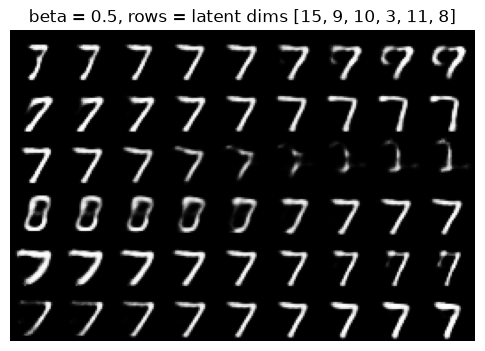

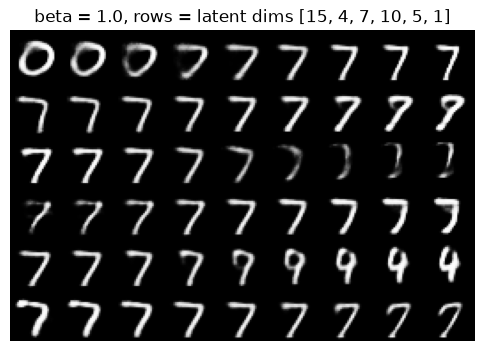

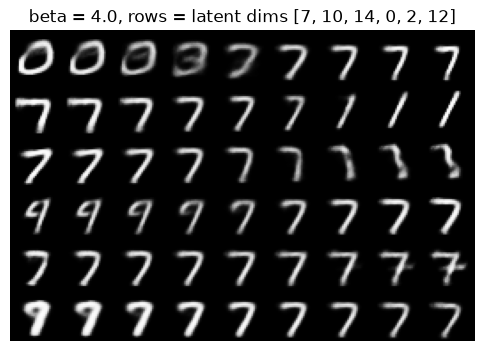

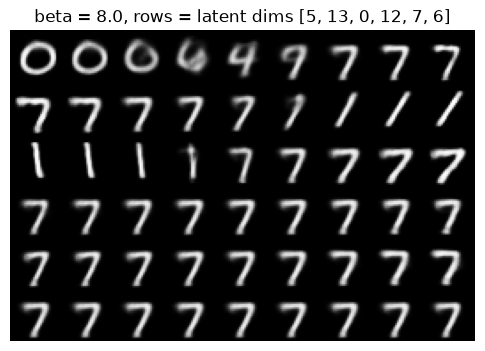

In [80]:
@torch.no_grad()
def traverse(model, x, dims, values):
    model.eval()
    mu, _ = model.encode(x.unsqueeze(0).to(device))
    rows = []
    for d in dims:
        z = mu.repeat(len(values), 1)
        z[:, d] = values
        rows.append(model.decode(z).cpu())
    return torch.cat(rows)

x0 = test_set[0][0]
values = torch.linspace(-3, 3, 9, device=device)
for b in bs:
    dims = kl_dims[b].argsort(descending=True)[:6].tolist()
    imgs = traverse(beta_models[b], x0, dims, values)
    plt.figure(figsize=(6, 4.2))
    plt.imshow(vutils.make_grid(imgs, nrow=len(values), padding=1).permute(1, 2, 0))
    plt.title(f'beta = {b}, rows = latent dims {dims}')
    plt.axis('off')
    plt.show()